# 💰 QuickLoan — The Great Model Bake-Off
### Credit-risk modelling, ensemble learning and money-based model selection

**1. Introduction.** QuickLoan is a (fictional) UAE fintech issuing small personal loans. Every application ends in
*approve* or *reject*. This notebook builds ten classifiers — three single models and seven ensembles covering
**Voting, Bagging, Boosting and Stacking** — scores them all on one common holdout, and recommends which one to deploy
**in money terms, not accuracy terms**.

**2. Business objective.** Mistakes are asymmetric:

| | Model approves (0) | Model rejects (1) |
|---|---|---|
| **Actually repays** | +20 % × loan (interest earned) | 0 (interest lost) |
| **Actually defaults** | −100 % × loan (principal lost) | 0 (loss avoided) |

*Money saved* = how much better a model does than approving everyone
= principal of caught defaulters − 20 % × principal of rejected good customers.

**Workflow and leakage rules.** All modelling code lives in the `quickloan` package and is shared with
`train_models.py`, so the notebook and the script produce identical artifacts. The test set (25 %, `random_state=1`,
stratified) is opened **once**, in Section 17. Feature engineering, class weighting, hyperparameters, thresholds,
feature importance, calibration and the deployment choice are all decided on the 4,500 training loans with 5-fold
stratified CV.

**Beyond the brief's core:** an untuned weak-learner baseline (Step 2), bootstrap confidence intervals on every
model's money saved, business thresholds re-optimised for any interest assumption, a with/without-age fairness check,
a calibrated deployment model, and exact reason codes for individual decisions (Sections 19–20).

## Executive summary
1. **Accuracy hides the money.** All ten models fall within **0.9 accuracy points**, yet money saved
   ranges over **AED 2,256,440** on the same 1,500 test loans.
2. **Leaderboard champion: Stacking**, saving **AED 4,891,400** versus approving everyone
   (0.50 threshold, 20 % interest) — but it wins only 44 % of bootstrap resamples and 4 other
   models are statistically tied with it ([§19c](#s19c)). It was selected using the common holdout benchmark for
   assignment comparison, so its figure is a model-ranking outcome, not an independent estimate of deployment
   performance.
3. **Recommended deployment: Gradient Boosting at a 0.16 threshold**, chosen on training
   cross-validation before the test set was opened. It saves **AED 5,943,420** on the test set
   (recall 54.3 %) — the threshold is the biggest money lever ([§17a](#s17), [§21](#s21)).
   Items 2 and 3 are different evaluations — **A**, all models at a common 0.50 threshold, and **C**, the deployment
   policy chosen on training data — and both use the same money-saved formula ([§17](#s17)).
4. **The selection procedure itself is validated.** Nested cross-validation (5 outer × 5 inner folds, training data
   only — evaluation **B**) re-ran the whole selection: it chose Gradient Boosting in 3 of 5
   folds and earned **AED 4,133,827 per 1,000 loans** (sd 295,127) on rows it never
   saw; no alternative was materially better ([§17c](#s17c)).
5. **Age is not needed:** without it the deployed model saves AED 28,800 *more*, within noise ([§20d](#s20d)).
6. **Every decision is explainable** with exact reason codes, and the deployed model's score is well calibrated
   ([§20e](#s20e), [§20f](#s20f)). The final cell re-checks every figure in this summary.

## Rubric map (30 marks + 3 stretch)
| # | Criterion | Marks | Where to find it |
|---|---|---:|---|
| 1 | Clean load, encode, train/test split (no leakage) | 3 | [§3 Load](#s3) · [§4 Validation](#s4) · [§8 Split](#s8) · [§7 Encoding pipeline](#s7) |
| 2 | Weak single models built + evaluated | 4 | [§9a–9c](#s9a) · [§17d metrics](#s17d) · [§19a untuned weak learner](#s19a) |
| 3 | Voting correctly built | 3 | [§10](#s10) |
| 4 | Bagging / Random Forest correctly built | 3 | [§11](#s11) · [§12](#s12) |
| 5 | Boosting (incl. XGBoost) correctly built | 4 | [§13 AdaBoost](#s13) · [§14 Gradient Boosting](#s14) · [§15 XGBoost](#s15) |
| 6 | Stacking correctly built | 4 | [§16](#s16) |
| 7 | Leaderboard with accuracy, recall **and** money saved | 4 | [§19](#s19) · [§19b charts](#s19b) · [§19c confidence intervals](#s19c) |
| 8 | Verdict on business grounds, accuracy-vs-money insight | 3 | [§21](#s21) |
| 9 | Code quality & interpretation | 2 | `quickloan/` package + 200 automated tests · a "Reading it" note under every result |
| ★ | Stretch: dashboard with decision + money cards | +3 | `app.py` · `loan_model.joblib` (also runs in the instructor's starter `app.py`) · [§22](#s22) |

The order is the brief's Steps 1–5. The only deliberate reordering: the split ([§8](#s8)) comes *before* feature
engineering ([§6](#s6)), so no modelling decision can see the test set.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib as mpl
from IPython.display import display, Markdown
from quickloan import config as C, data as D, features as FE, finance as F, models as M, evaluation as E, training as T, artifacts as A

P = C.PALETTE
mpl.rcParams.update({
    "figure.facecolor": P["bg1"], "axes.facecolor": P["bg2"], "savefig.facecolor": P["bg1"],
    "axes.edgecolor": "#2A3A55", "axes.labelcolor": P["t2"], "axes.titlecolor": P["t1"], "text.color": P["t2"],
    "xtick.color": P["t2"], "ytick.color": P["t2"], "grid.color": "#22324B", "axes.grid": True, "grid.alpha": .6,
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.labelsize": 11, "legend.frameon": False,
    "font.family": "DejaVu Sans", "figure.dpi": 110,
})
GOOD, BAD = P["emerald"], P["neg"]
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 160)
print("XGBoost available:", M.HAS_XGB, "| model label:", M.XGB_LABEL)

XGBoost available: True | model label: XGBoost


<a id="s3"></a>

## 3. Data inspection

In [2]:
df = D.load_loans()            # resolves loans.csv / loans(1).csv and runs hard validation
print("Shape:", df.shape)
display(df.head())
display(df.dtypes.to_frame("dtype").T)
print("Target counts:", df[C.TARGET].value_counts().to_dict(), f"| default rate {df[C.TARGET].mean():.2%}")

Shape: (6000, 11)


,age,annual_income,loan_amount,loan_term_months,employment_years,credit_history_months,num_existing_loans,past_defaults,debt_to_income,home_ownership,default
0,24,"133,500.0000","46,300.0000",24,4.4000,170,0,0,0.3500,rent,0
1,55,"33,400.0000","40,600.0000",24,1.6000,100,1,0,1.2200,mortgage,0
2,49,"152,100.0000","45,800.0000",36,14.1000,253,1,0,0.3000,rent,0
3,40,"67,400.0000","32,800.0000",36,1.4000,294,0,0,0.4900,rent,0
4,40,"143,900.0000","68,900.0000",24,14.5000,289,1,1,0.4800,rent,0


,age,annual_income,loan_amount,loan_term_months,employment_years,credit_history_months,num_existing_loans,past_defaults,debt_to_income,home_ownership,default
dtype,int64,float64,float64,int64,float64,int64,int64,int64,float64,str,int64


Target counts: {0: 5247, 1: 753} | default rate 12.55%


<a id="s4"></a>

## 4. Data-quality validation
Hard checks (schema, missing values, binary target, positive amounts) are enforced by `D.validate`; the audit below
adds duplicates, ranges, percentiles, IQR outliers and logical-consistency checks.

In [3]:
audit = D.quality_audit(df)
print(f"Missing values: {audit['missing']} | duplicate rows: {audit['duplicates']}")
print("home_ownership levels:", audit["categories"])
display(pd.Series(audit["sanity"], name="passes").to_frame())
display(audit["describe"].round(2))
display(pd.Series(audit["iqr_outliers"], name="IQR outliers (1.5×)").to_frame().T)
ie = audit["implausible_employment"]
print(f"Plausibility flag - employment_years > age - 16: {ie['n']} rows ({ie['share']:.1%}), "
      f"default rate {ie['default_rate']:.1%}, oldest such applicant {ie['max_age']}. Decision: {ie['decision']}")
display(df.loc[df.employment_years > df.age - 16, ["age", "employment_years"]].assign(age_band=lambda d: pd.cut(d.age, [20, 25, 29, 39, 64])).age_band.value_counts().sort_index().to_frame("flagged rows"))

Missing values: 0 | duplicate rows: 0
home_ownership levels: {'rent': 2926, 'mortgage': 1803, 'own': 1271}


,passes
loan_amount_positive,True
annual_income_positive,True
target_binary,True
home_ownership_known,True
employment_le_age_minus_16,False
loan_term_in_allowed_set,True
non_negative_counts,True


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
age,"6,000.0000",42.4500,12.6900,21.0000,21.0000,23.0000,31.0000,42.0000,54.0000,62.0000,64.0000,64.0000
annual_income,"6,000.0000","96,184.6300","36,000.7900","30,400.0000","39,500.0000","48,700.0000","70,200.0000","90,200.0000","115,600.0000","163,605.0000","203,201.0000","361,400.0000"
loan_amount,"6,000.0000","50,536.5700","26,252.7200","6,700.0000","11,600.0000","17,000.0000","30,900.0000","45,800.0000","64,400.0000","101,100.0000","130,702.0000","210,700.0000"
loan_term_months,"6,000.0000",33.6500,14.3700,12.0000,12.0000,12.0000,24.0000,36.0000,48.0000,60.0000,60.0000,60.0000
employment_years,"6,000.0000",5.9800,4.2700,0.0000,0.4000,1.0000,2.8000,5.0000,8.1000,14.0000,19.9000,35.0000
credit_history_months,"6,000.0000",149.2800,86.6100,0.0000,2.9900,15.0000,75.0000,150.0000,224.0000,286.0000,296.0000,299.0000
num_existing_loans,"6,000.0000",1.1000,1.0400,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,3.0000,4.0000,6.0000
past_defaults,"6,000.0000",0.2400,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0000,2.0000,4.0000
debt_to_income,"6,000.0000",0.6000,0.4000,0.0300,0.1000,0.1600,0.3200,0.5100,0.7600,1.3700,2.0100,3.0000


,age,annual_income,loan_amount,loan_term_months,employment_years,credit_history_months,num_existing_loans,past_defaults,debt_to_income
IQR outliers (1.5×),0,147,157,0,190,0,4,1287,257


Plausibility flag - employment_years > age - 16: 278 rows (4.6%), default rate 8.3%, oldest such applicant 47. Decision: kept - flagged, not removed (no evidence of which field is wrong; removal would change the assignment's reference split)


,flagged rows
age_band,
"(20, 25]",217
"(25, 29]",41
"(29, 39]",17
"(39, 64]",3


**Reading the audit.** No missing values or duplicates; amounts are positive, the target is binary, loan terms are
one of 12/24/36/48/60 and counts are non-negative. IQR "outliers" are the long right tails of income and loan size —
legitimate large borrowers, not errors.

**One plausibility flag:** some applicants report more years employed than years since age 16 (see below — almost all
aged 21–29, e.g. a 21-year-old with 16 years of employment). The data is synthetic and there is no evidence which field
is wrong, so these rows are **kept and flagged, not removed**: deleting them would be an unjustified intervention and
would also change the assignment's reference split. The simulator warns when a user enters such a combination.

### 4.2 The `debt_to_income` inconsistency

In [4]:
mm = audit["dti_mismatch"]
print(f"{len(mm)} rows where stored debt_to_income != round(loan_amount / annual_income, 2)")
display(mm)
print(mm["reason"].value_counts())

14 rows where stored debt_to_income != round(loan_amount / annual_income, 2)


,loan_amount,annual_income,debt_to_income,raw_ratio,reason
603,"28,500.0000","60,000.0000",0.4700,0.4750,half-way rounding
939,"105,000.0000","30,400.0000",3.0000,3.4539,capped at 3.00
1411,"130,000.0000","40,100.0000",3.0000,3.2419,capped at 3.00
1634,"105,100.0000","34,700.0000",3.0000,3.0288,capped at 3.00
1836,"139,100.0000","43,000.0000",3.0000,3.2349,capped at 3.00
2081,"58,200.0000","40,000.0000",1.4500,1.4550,half-way rounding
2175,"23,600.0000","80,000.0000",0.2900,0.2950,half-way rounding
2501,"116,700.0000","35,500.0000",3.0000,3.2873,capped at 3.00
2727,"125,400.0000","37,200.0000",3.0000,3.3710,capped at 3.00
3430,"114,700.0000","30,600.0000",3.0000,3.7484,capped at 3.00


reason
capped at 3.00       8
half-way rounding    6
Name: count, dtype: int64


**Decision.** Eight values are capped at the dataset maximum 3.00 and six are half-way ratios (x.xx5) stored rounded
down. Both are recording conventions, not corrupt data, so **training uses the values exactly as recorded**. The
dashboard's simulator re-creates the same quantity as a documented *loan-to-income proxy*
(`loan_amount / annual_income`, rounded to 2 dp, capped at 3.00). It is **not** a conventional debt-to-income ratio,
which would use total monthly debt service.

<a id="s5"></a>

## 5. Exploratory data analysis

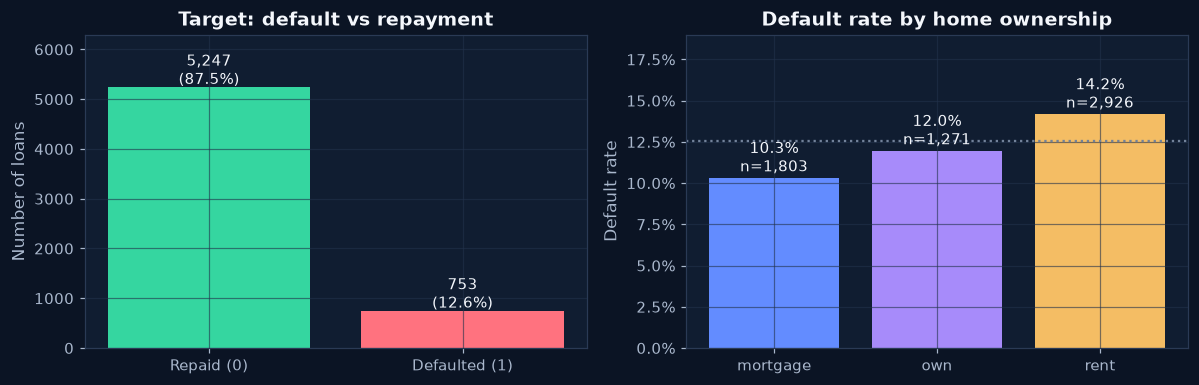

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
vc = df[C.TARGET].value_counts().sort_index()
ax[0].bar(["Repaid (0)", "Defaulted (1)"], vc.values, color=[GOOD, BAD])
for i, v in enumerate(vc.values): ax[0].text(i, v + 60, f"{v:,}\n({v/len(df):.1%})", ha="center", color=P["t1"])
ax[0].set(title="Target: default vs repayment", ylabel="Number of loans", ylim=(0, vc.max() * 1.2))
ho = df.groupby("home_ownership")[C.TARGET].agg(["size", "mean"]).sort_values("mean")
ax[1].bar(ho.index, ho["mean"], color=[P["blue"], P["violet"], P["amber"]])
for i, (n, r) in enumerate(zip(ho["size"], ho["mean"])): ax[1].text(i, r + .004, f"{r:.1%}\nn={n:,}", ha="center", color=P["t1"])
ax[1].axhline(df[C.TARGET].mean(), ls=":", color=P["t3"]); ax[1].set(title="Default rate by home ownership", ylabel="Default rate", ylim=(0, .19))
ax[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); plt.tight_layout(); plt.show()

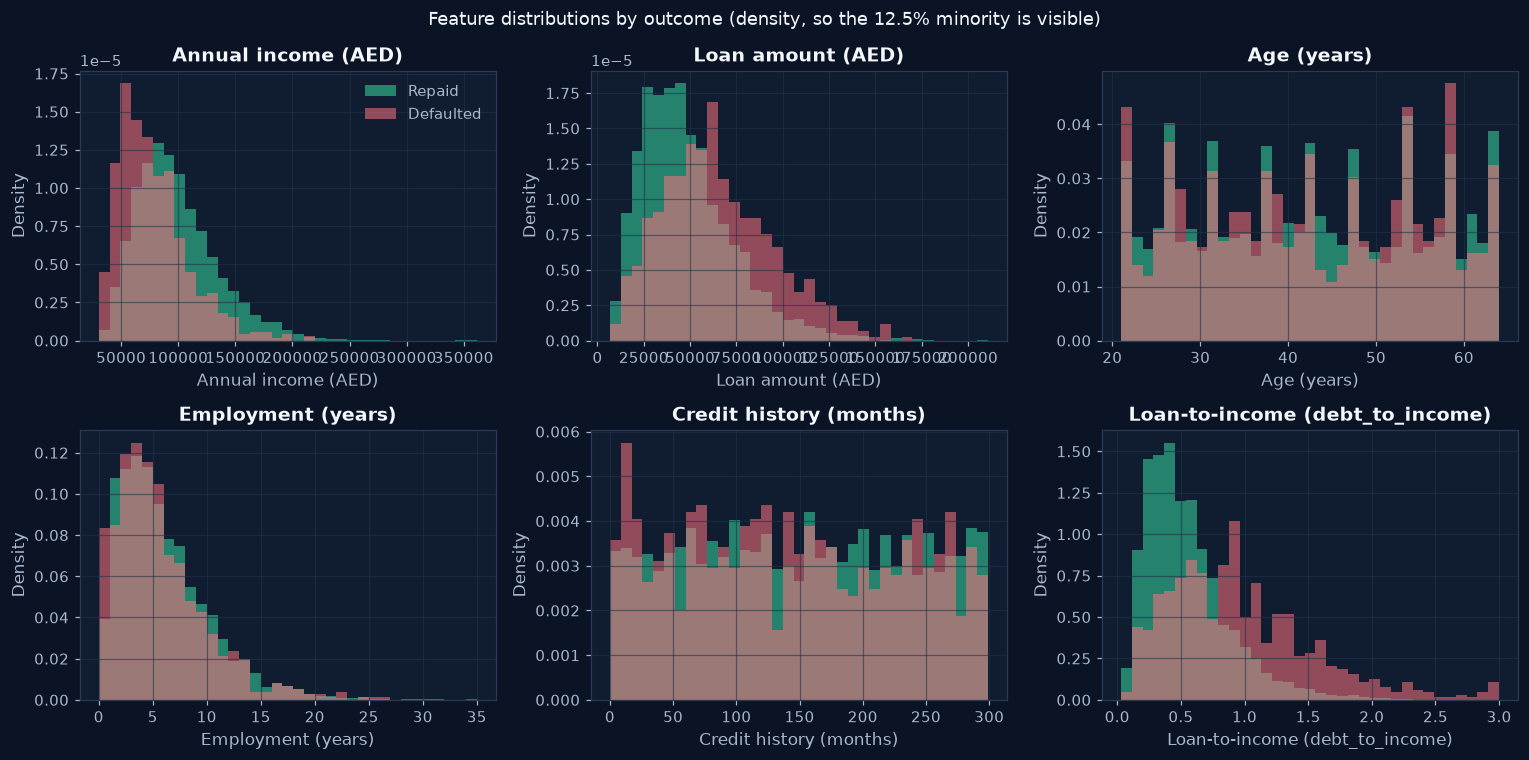

In [6]:
cols = [("annual_income", "Annual income (AED)"), ("loan_amount", "Loan amount (AED)"), ("age", "Age (years)"),
        ("employment_years", "Employment (years)"), ("credit_history_months", "Credit history (months)"),
        ("debt_to_income", "Loan-to-income (debt_to_income)")]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for a, (c, lab) in zip(axes.ravel(), cols):
    bins = np.histogram_bin_edges(df[c], bins=35)
    a.hist(df.loc[df[C.TARGET] == 0, c], bins=bins, density=True, alpha=.55, color=GOOD, label="Repaid")
    a.hist(df.loc[df[C.TARGET] == 1, c], bins=bins, density=True, alpha=.55, color=BAD, label="Defaulted")
    a.set(title=lab, xlabel=lab, ylabel="Density")
axes[0, 0].legend(); plt.suptitle("Feature distributions by outcome (density, so the 12.5% minority is visible)", color=P["t1"]); plt.tight_layout(); plt.show()

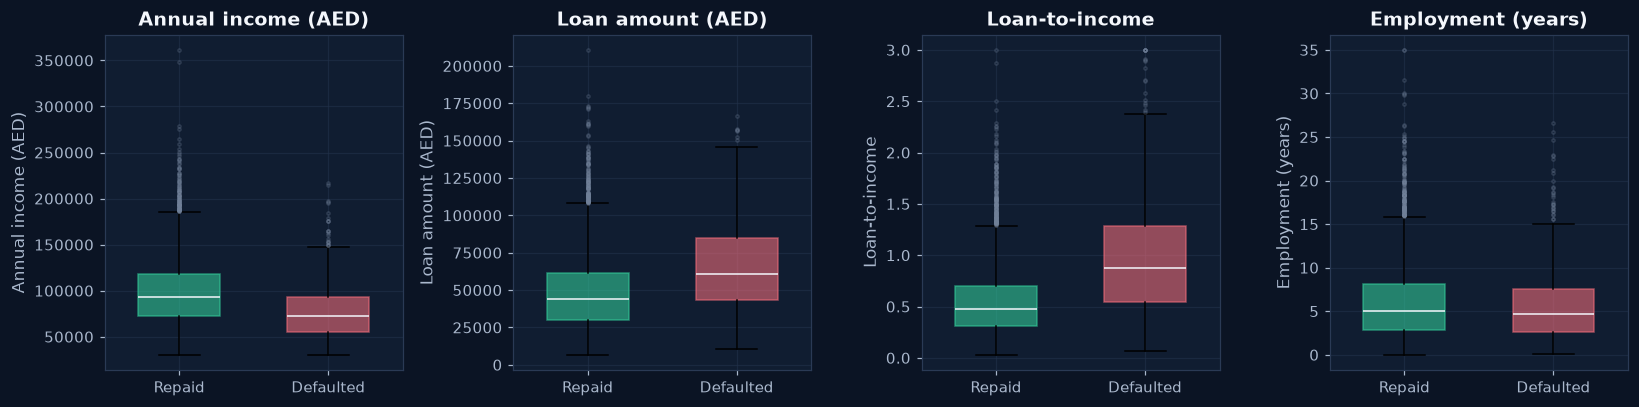

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for a, (c, lab) in zip(axes, [("annual_income", "Annual income (AED)"), ("loan_amount", "Loan amount (AED)"),
                              ("debt_to_income", "Loan-to-income"), ("employment_years", "Employment (years)")]):
    bp = a.boxplot([df.loc[df[C.TARGET] == 0, c], df.loc[df[C.TARGET] == 1, c]], tick_labels=["Repaid", "Defaulted"],
                   patch_artist=True, widths=.55, medianprops=dict(color=P["t1"]), flierprops=dict(markersize=2, alpha=.3, markeredgecolor=P["t3"]))
    for patch, col in zip(bp["boxes"], [GOOD, BAD]): patch.set(facecolor=col, alpha=.55, edgecolor=col)
    a.set(title=lab, ylabel=lab)
plt.tight_layout(); plt.show()

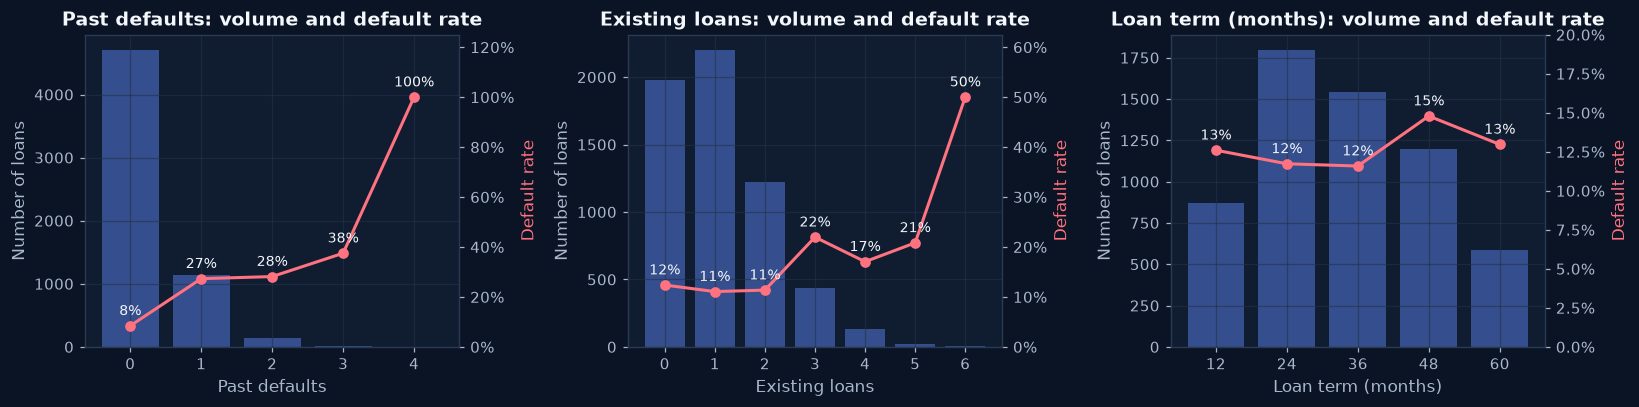

past_defaults          0          1        2       3      4
size          4,713.0000 1,135.0000 135.0000 16.0000 1.0000
mean              0.0844     0.2731   0.2815  0.3750 1.0000


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for a, c, lab in [(axes[0], "past_defaults", "Past defaults"), (axes[1], "num_existing_loans", "Existing loans"),
                  (axes[2], "loan_term_months", "Loan term (months)")]:
    g = df.groupby(c)[C.TARGET].agg(["size", "mean"])
    a2 = a.twinx(); a2.grid(False)
    a.bar(g.index.astype(str), g["size"], color=P["blue"], alpha=.45, label="Loans")
    a2.plot(g.index.astype(str), g["mean"], "o-", color=BAD, lw=2, label="Default rate")
    for x, (n, r) in zip(g.index.astype(str), zip(g["size"], g["mean"])): a2.annotate(f"{r:.0%}", (x, r), textcoords="offset points", xytext=(0, 7), ha="center", color=P["t1"], fontsize=9)
    a.set(title=f"{lab}: volume and default rate", xlabel=lab, ylabel="Number of loans"); a2.set_ylabel("Default rate", color=BAD)
    a2.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); a2.set_ylim(0, max(g["mean"].max() * 1.25, .2))
plt.tight_layout(); plt.show()
print(df.groupby("past_defaults")[C.TARGET].agg(["size", "mean"]).T)

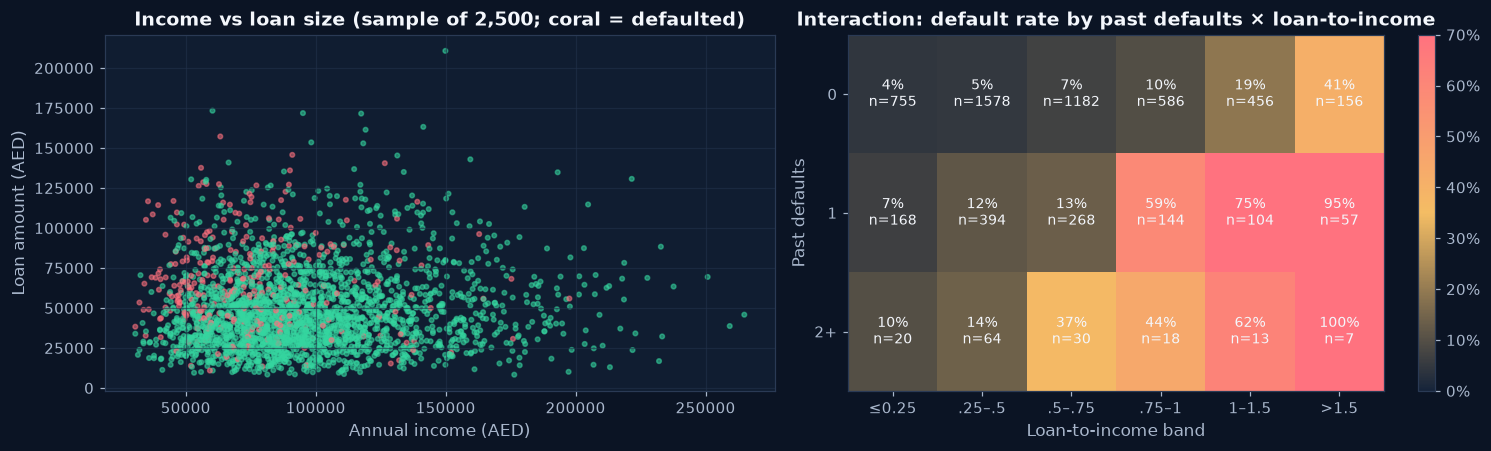

In [9]:
d = df.assign(lti_band=pd.cut(df["debt_to_income"], [0, .25, .5, .75, 1, 1.5, 3.01], labels=["≤0.25", ".25–.5", ".5–.75", ".75–1", "1–1.5", ">1.5"]),
              pd_band=df["past_defaults"].clip(upper=2).map({0: "0", 1: "1", 2: "2+"}))
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
s = df.sample(2500, random_state=1)
ax[0].scatter(s["annual_income"], s["loan_amount"], c=np.where(s[C.TARGET] == 1, BAD, GOOD), s=9, alpha=.55)
ax[0].set(title="Income vs loan size (sample of 2,500; coral = defaulted)", xlabel="Annual income (AED)", ylabel="Loan amount (AED)")
pv = d.pivot_table(index="pd_band", columns="lti_band", values=C.TARGET, aggfunc="mean", observed=True)
im = ax[1].imshow(pv.values, cmap=mpl.colors.LinearSegmentedColormap.from_list("q", [P["bg3"], P["amber"], BAD]), aspect="auto", vmin=0, vmax=.7)
for i in range(pv.shape[0]):
    for j in range(pv.shape[1]):
        n = ((d["pd_band"] == pv.index[i]) & (d["lti_band"] == pv.columns[j])).sum()
        ax[1].text(j, i, f"{pv.values[i, j]:.0%}\nn={n}", ha="center", va="center", color=P["t1"], fontsize=9)
ax[1].set(xticks=range(pv.shape[1]), xticklabels=pv.columns, yticks=range(pv.shape[0]), yticklabels=pv.index,
          title="Interaction: default rate by past defaults × loan-to-income", xlabel="Loan-to-income band", ylabel="Past defaults")
ax[1].grid(False); plt.colorbar(im, ax=ax[1], format=mpl.ticker.PercentFormatter(1)); plt.tight_layout(); plt.show()

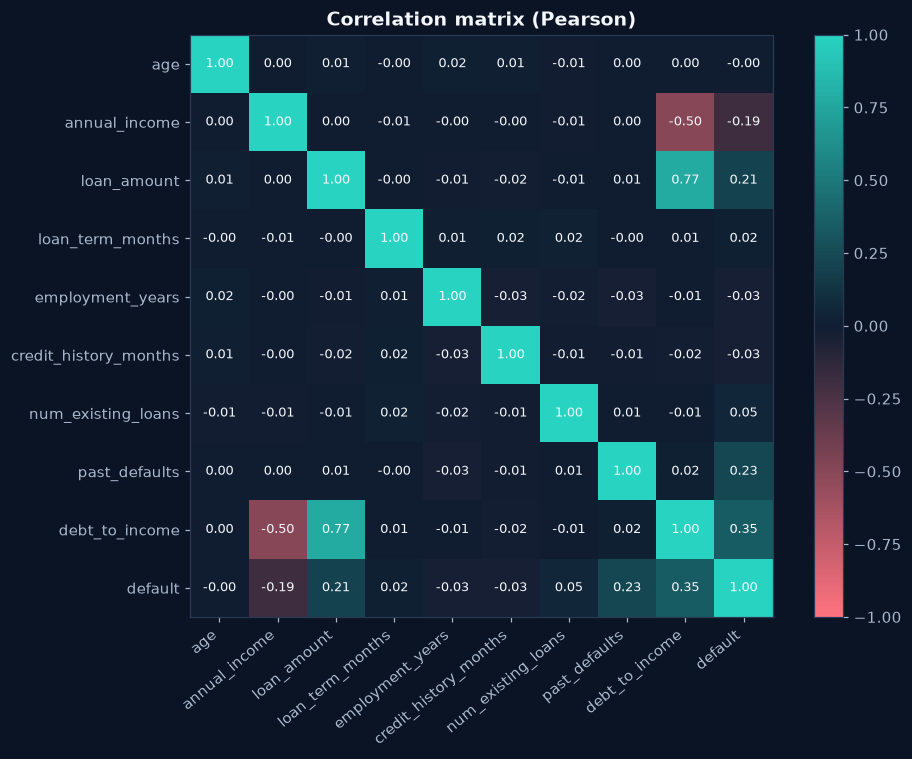

,corr with default
annual_income,-0.1921
employment_years,-0.0267
credit_history_months,-0.0266
age,-0.0017
loan_term_months,0.0192
num_existing_loans,0.0502
loan_amount,0.2105
past_defaults,0.2280
debt_to_income,0.3452


In [10]:
corr = df.drop(columns="home_ownership").corr()
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap=mpl.colors.LinearSegmentedColormap.from_list("d", [BAD, P["bg2"], P["teal"]]), vmin=-1, vmax=1)
ax.set(xticks=range(len(corr)), yticks=range(len(corr)), title="Correlation matrix (Pearson)")
ax.set_xticklabels(corr.columns, rotation=40, ha="right"); ax.set_yticklabels(corr.index); ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=8.5, color=P["t1"])
plt.colorbar(im, ax=ax, fraction=.046); plt.tight_layout(); plt.show()
display(corr[C.TARGET].drop(C.TARGET).sort_values().to_frame("corr with default"))

In [11]:
# Segmented financial view: where the principal at risk sits
seg = d.groupby("lti_band", observed=True).agg(loans=("loan_amount", "size"), principal=("loan_amount", "sum"),
          default_principal=("loan_amount", lambda s: s[d.loc[s.index, C.TARGET] == 1].sum()))
seg["share_of_all_default_principal"] = seg["default_principal"] / seg["default_principal"].sum()
seg["loss_rate_on_principal"] = seg["default_principal"] / seg["principal"]
display(seg.style.format({"principal": "AED {:,.0f}", "default_principal": "AED {:,.0f}",
        "share_of_all_default_principal": "{:.1%}", "loss_rate_on_principal": "{:.1%}"}))

,loans,principal,default_principal,share_of_all_default_principal,loss_rate_on_principal
lti_band,,,,,
≤0.25,943,"AED 21,005,500","AED 897,200",1.8%,4.3%
.25–.5,2036,"AED 79,961,500","AED 4,940,100",10.1%,6.2%
.5–.75,1480,"AED 81,055,100","AED 6,947,600",14.2%,8.6%
.75–1,748,"AED 50,839,400","AED 10,059,300",20.5%,19.8%
1–1.5,573,"AED 47,501,700","AED 13,502,100",27.5%,28.4%
>1.5,220,"AED 22,856,200","AED 12,691,400",25.9%,55.5%


**EDA conclusions.**
* 12.55 % of loans default — a clear minority class, so accuracy is dominated by repayers.
* **Past defaults** is the strongest single signal: any prior default roughly triples the default rate (≈8 % → ≈27 %).
* **Loan-to-income** (`debt_to_income`) has the highest linear correlation with default (≈0.35); income is protective
  and larger loans riskier. High loan-to-income bands carry a disproportionate share of defaulted principal, which is
  exactly what the money metric rewards catching.
* Renters default more than owners and mortgagors; age, term and credit-history length are weak on their own.
* The interaction heatmap shows risk compounding: past defaults **and** a high loan-to-income ratio together.

<a id="s8"></a>

## 8. Train/test split *(done before feature engineering so no decision can see the test set)*
Assignment settings: 25 % test, `random_state=1`, stratified on `default`. Test loan amounts are taken from `X_test`
itself, so they stay aligned with every prediction by construction.

In [12]:
split = D.make_split(df)
check = D.reconcile_split(split)
display(pd.DataFrame(check).T)
assert all(v["match"] for v in check.values()), "Split does not reconcile with the instructor reference"
print(f"Train {len(split.y_train):,} ({split.y_train.mean():.2%} default) | Test {len(split.y_test):,} ({split.y_test.mean():.2%} default)")

,reference,actual,match
n_test,1500,1500,True
n_def,188,188,True
n_good,1312,1312,True
total_def_loans,"12,271,900.0000","12,271,900.0000",True
total_good_loans,"62,945,000.0000","62,945,000.0000",True


Train 4,500 (12.56% default) | Test 1,500 (12.53% default)


Every reference value (1,500 test loans, 188 defaulters, AED 12,271,900 defaulted principal, AED 62,945,000 repaid principal) reconciles exactly.

<a id="s6"></a>

## 6. Feature engineering
Candidates are deterministic row-wise functions of the applicant's own inputs (no fitting, no target information).
They run inside the model pipeline, so the saved artifact computes them identically at prediction time.
A principal burden is **not** an EMI: the data has no interest rate or amortisation schedule.

In [13]:
display(pd.DataFrame([(k, f, m) for k, (f, m) in FE.CANDIDATES.items()], columns=["feature", "formula", "financial meaning"]))
eng = FE.add_features(split.X_train, list(FE.CANDIDATES))
new = list(FE.CANDIDATES)
display(eng[new].describe().T.round(3))
red = eng[new + ["loan_amount", "annual_income", "debt_to_income", "credit_history_months", "past_defaults", "employment_years"]].corr().loc[new]
display(red.round(2).style.background_gradient(cmap="RdYlGn_r", vmin=-1, vmax=1).set_caption("Redundancy with existing variables (training set)"))

,feature,formula,financial meaning
0,monthly_principal_burden,loan_amount / loan_term_months,Principal the borrower must retire each month ...
1,annual_principal_burden_ratio,(loan_amount / loan_term_months * 12) / annual...,Share of yearly income consumed by principal r...
2,credit_history_years,credit_history_months / 12,"Same information in years. A linear rescaling,..."
3,log_annual_income,ln(annual_income),Diminishing marginal effect of income; tames t...
4,has_past_default,1 if past_defaults > 0 else 0,Any prior default at all - credit officers tre...
5,employment_share_of_adult_life,"employment_years / max(age - 18, 1)",Career stability relative to age: 5 years mean...


,count,mean,std,min,25%,50%,75%,max
monthly_principal_burden,"4,500.0000","1,904.2340","1,533.0780",141.6670,902.6040,"1,458.3330","2,380.2080","17,558.3330"
annual_principal_burden_ratio,"4,500.0000",0.2700,0.2540,0.0110,0.1140,0.1940,0.3330,3.4540
credit_history_years,"4,500.0000",12.3520,7.1720,0.0000,6.2500,12.3330,18.5830,24.9170
log_annual_income,"4,500.0000",11.4090,0.3670,10.3220,11.1630,11.4140,11.6570,12.7980
has_past_default,"4,500.0000",0.2120,0.4080,0.0000,0.0000,0.0000,0.0000,1.0000
employment_share_of_adult_life,"4,500.0000",0.3850,0.5140,0.0000,0.1140,0.2280,0.4420,7.3000


,monthly_principal_burden,annual_principal_burden_ratio,credit_history_years,log_annual_income,has_past_default,employment_share_of_adult_life,loan_amount,annual_income,debt_to_income,credit_history_months,past_defaults,employment_years
monthly_principal_burden,1.000000,0.850000,-0.020000,0.010000,0.030000,-0.030000,0.640000,0.000000,0.490000,-0.020000,0.020000,-0.020000
annual_principal_burden_ratio,0.850000,1.000000,-0.020000,-0.380000,0.030000,-0.020000,0.540000,-0.350000,0.710000,-0.020000,0.030000,-0.020000
credit_history_years,-0.020000,-0.020000,1.000000,-0.000000,-0.010000,-0.020000,-0.030000,-0.000000,-0.020000,1.000000,-0.010000,-0.020000
log_annual_income,0.010000,-0.380000,-0.000000,1.000000,-0.010000,-0.020000,0.010000,0.970000,-0.550000,-0.000000,-0.010000,-0.000000
has_past_default,0.030000,0.030000,-0.010000,-0.010000,1.000000,-0.030000,0.020000,-0.010000,0.030000,-0.010000,0.930000,-0.040000
employment_share_of_adult_life,-0.030000,-0.020000,-0.020000,-0.020000,-0.030000,1.000000,-0.030000,-0.010000,-0.000000,-0.020000,-0.030000,0.510000


**Validation protocol.** Each feature is added *on its own* to a scaled logistic regression and to gradient boosting
and scored by 5-fold CV average precision (PR-AUC) on the training set. A feature is kept only if it lifts mean PR-AUC
by more than **0.002**; `credit_history_years` is a pure rescaling and acts as a control for the noise floor. The
retained set is then re-checked in combination.

In [14]:
fe_table, FEATURES = T.feature_engineering_study(split, verbose=False)
display(fe_table.style.format({c: "{:.4f}" for c in ["LR_pr_auc", "GB_pr_auc", "LR_roc_auc", "GB_roc_auc"]} | {"delta_mean_pr_auc": "{:+.4f}"}))
print("Retained engineered features:", FEATURES)

,feature_set,formula,LR_pr_auc,GB_pr_auc,LR_roc_auc,GB_roc_auc,delta_mean_pr_auc,decision
0,original 10 features,-,0.4798,0.5083,0.7881,0.7891,+0.0000,baseline
1,+ monthly_principal_burden,loan_amount / loan_term_months,0.4808,0.5086,0.7887,0.7871,+0.0007,rejected
2,+ annual_principal_burden_ratio,(loan_amount / loan_term_months * 12) / annual_income,0.4810,0.5049,0.7887,0.7884,-0.0011,rejected
3,+ credit_history_years,credit_history_months / 12,0.4798,0.5115,0.7882,0.7883,+0.0016,rejected
4,+ log_annual_income,ln(annual_income),0.4832,0.5065,0.7883,0.7875,+0.0008,rejected
5,+ has_past_default,1 if past_defaults > 0 else 0,0.5050,0.5072,0.7902,0.7870,+0.0121,RETAINED
6,+ employment_share_of_adult_life,"employment_years / max(age - 18, 1)",0.4795,0.5207,0.7880,0.7923,+0.0060,RETAINED
7,+ has_past_default + employment_share_of_adult_life,combined,0.5048,0.5165,0.7900,0.7884,+0.0166,RETAINED


Retained engineered features: ('has_past_default', 'employment_share_of_adult_life')


**Outcome.** `has_past_default` gives the largest lift (prior default is a step change, not a linear count effect) and
`employment_share_of_adult_life` adds a career-stability signal; together they pass the combined test and are kept.
The principal-burden ratios, log income and the rescaled control fall inside the noise band and are **rejected**:
they are largely redundant with `debt_to_income`, `loan_amount` and `annual_income`.

<a id="s7"></a>

## 7. Preprocessing architecture
`FeatureEngineer → ColumnTransformer(OneHotEncoder(handle_unknown="ignore") on home_ownership + StandardScaler or passthrough) → estimator`.
Scaling is applied for Logistic Regression and KNN (distance- and penalty-based); trees get raw values. Each pipeline
is fitted on training data only — inside CV this happens fold by fold — and an unseen home-ownership value is encoded as
all zeros instead of crashing.

In [15]:
pipe = M.make_pipeline("Logistic Regression", FEATURES)
display(pipe)
pre = pipe[:-1].fit(split.X_train, split.y_train)
print("Model input columns:", list(pre.get_feature_names_out()))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('prep', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,features,"('has_past_default', ...)"
,drop,()
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",StandardScaler()
,"verbose_feature_

Model input columns: ['home_ownership_rent', 'home_ownership_own', 'home_ownership_mortgage', 'age', 'annual_income', 'loan_amount', 'loan_term_months', 'employment_years', 'credit_history_months', 'num_existing_loans', 'past_defaults', 'debt_to_income', 'has_past_default', 'employment_share_of_adult_life']


<a id="s9"></a>

## 9–16. Model development
Each directly tuned model gets a **small, transparent grid** searched with 5-fold stratified CV, scored by average
precision. Class weights stay at their default here; their effect is studied separately in Section 17.

In [16]:
TUNED, PARAMS, ROWS, GRIDS = {}, {}, [], {}
def tune(name):
    est, prm, row = T.tune_one(name, split, FEATURES, verbose=False)
    GRIDS[name] = row.pop("_grid"); TUNED[name], PARAMS[name] = est, prm; ROWS.append(row)
    print(f"{name}: best CV PR-AUC {row['cv_pr_auc']:.4f} from {row['n_candidates']} candidates in {row['seconds']}s")
    print("  selected:", {k.replace('clf__', ''): v for k, v in prm.items()})
    display(GRIDS[name].head(5))

<a id="s9a"></a>

### 9a. Decision Tree (single)
Complexity controls: `max_depth`, `min_samples_leaf`, `min_samples_split`. **Interpretable** — a short list of if-then rules — but high-variance: small data changes can reshape the tree. Tuning makes this tree much stronger than the brief's 'weak' learner, so Section 19 also reports an **untuned depth-3 tree** as the weak-learner baseline (shown beside, not inside, the ten-model leaderboard).

In [17]:
tune("Decision Tree")

Decision Tree: best CV PR-AUC 0.4941 from 30 candidates in 4.6s
  selected: {'max_depth': 6, 'min_samples_leaf': 50, 'min_samples_split': 20}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.4941,0.0423,1
1,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.4941,0.0423,1
2,"{'clf__max_depth': 5, 'clf__min_samples_leaf':...",0.4928,0.0383,3
3,"{'clf__max_depth': 5, 'clf__min_samples_leaf':...",0.4928,0.0383,3
4,"{'clf__max_depth': 8, 'clf__min_samples_leaf':...",0.4897,0.0447,5


<a id="s9b"></a>

### 9b. Logistic Regression (single)
Scaled inputs, L2 penalty tuned through `C`. Coefficients are directly explainable, but it can only draw a linear boundary in the (engineered) feature space, so interactions such as past-default × loan-to-income are missed.

In [18]:
tune("Logistic Regression")

Logistic Regression: best CV PR-AUC 0.5070 from 7 candidates in 0.7s
  selected: {'C': 0.03}


,params,mean_test_score,std_test_score,rank_test_score
0,{'clf__C': 0.03},0.5070,0.0310,1
1,{'clf__C': 0.01},0.5064,0.0282,2
2,{'clf__C': 0.1},0.5061,0.0323,3
3,{'clf__C': 10.0},0.5049,0.0326,4
4,{'clf__C': 1.0},0.5048,0.0328,5


<a id="s9c"></a>

### 9c. KNN (single)
Distances are meaningless unless features share a scale — income in AED would otherwise swamp everything — so inputs are standardised. Searched: `n_neighbors`, `weights`, distance metric `p` (1 = Manhattan, 2 = Euclidean).

In [19]:
tune("KNN")

KNN: best CV PR-AUC 0.5132 from 24 candidates in 9.2s
  selected: {'n_neighbors': 75, 'p': 2, 'weights': 'distance'}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__n_neighbors': 75, 'clf__p': 2, 'clf__we...",0.5132,0.0523,1
1,"{'clf__n_neighbors': 101, 'clf__p': 2, 'clf__w...",0.5130,0.0572,2
2,"{'clf__n_neighbors': 151, 'clf__p': 1, 'clf__w...",0.5126,0.0587,3
3,"{'clf__n_neighbors': 101, 'clf__p': 1, 'clf__w...",0.5118,0.0535,4
4,"{'clf__n_neighbors': 51, 'clf__p': 2, 'clf__we...",0.5116,0.0521,5


<a id="s10"></a>

### 10. Voting (ensemble)
A **soft** vote averages the predicted default probabilities of the three tuned single models, so a confident model
counts for more than an unsure one. Mixing a tree, a linear model and a neighbourhood model gives genuinely different
errors to average out.

In [20]:
TUNED["Voting"] = M.make_voting(TUNED); PARAMS["Voting"] = T.ENSEMBLE_PARAMS["Voting"]
TUNED["Voting"]

,"estimators estimators: list of (str, estimator) tuplesInvoking the ``fit`` method on the ``VotingClassifier`` will fit clonesof those original estimators that will be stored in the class attribute``self.estimators_``. An estimator can be set to ``'drop'`` using:meth:`set_params`... versionchanged:: 0.21 ``'drop'`` is accepted. Using None was deprecated in 0.22 and support was removed in 0.24.","[('dt', ...), ('lr', ...), ...]"
,"voting voting: {'hard', 'soft'}, default='hard'If 'hard', uses predicted class labels for majority rule voting.Else if 'soft', predicts the class label based on the argmax ofthe sums of the predicted probabilities, which is recommended foran ensemble of well-calibrated classifiers.",'soft'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for ``fit``.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionadded:: 0.18",1
,"weights weights: array-like of shape (n_classifiers,), default=NoneSequence of weights (`float` or `int`) to weight the occurrences ofpredicted class labels (`hard` voting) or class probabilitiesbefore averaging (`soft` voting). Uses uniform weights if `None`.",None
,"flatten_transform flatten_transform: bool, default=TrueAffects shape of transform output only when voting='soft'If voting='soft' and flatten_transform=True, transform method returnsmatrix with shape (n_samples, n_classifiers * n_classes). Ifflatten_transform=False, it returns(n_classifiers, n_samples, n_classes).",True
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting will be printed as itis completed... versionadded:: 0.23",False
,features,"('has_past_default', ...)"
,drop,()
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'passthrough'
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will 

<a id="s11"></a>

### 11. Bagging (ensemble)
200 decision trees, each trained on a bootstrap sample of the rows; their probabilities are averaged. Deep trees have low bias but high variance — averaging many de-synchronised copies cancels much of that variance.

In [21]:
tune("Bagging")

Bagging: best CV PR-AUC 0.5233 from 6 candidates in 53.9s
  selected: {'estimator__min_samples_leaf': 10, 'max_samples': 0.6}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__estimator__min_samples_leaf': 10, 'clf_...",0.5233,0.0376,1
1,"{'clf__estimator__min_samples_leaf': 10, 'clf_...",0.5168,0.0402,2
2,"{'clf__estimator__min_samples_leaf': 5, 'clf__...",0.5163,0.0430,3
3,"{'clf__estimator__min_samples_leaf': 5, 'clf__...",0.5081,0.0384,4
4,"{'clf__estimator__min_samples_leaf': 1, 'clf__...",0.4957,0.0418,5


<a id="s12"></a>

### 12. Random Forest (ensemble, bagging family)
Bagging plus a random subset of features at every split (`max_features`), which de-correlates the trees further so the average reduces variance more than plain bagging can.

In [22]:
tune("Random Forest")

Random Forest: best CV PR-AUC 0.5336 from 12 candidates in 69.3s
  selected: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 10, 'min_samples_split': 2}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__max_depth': None, 'clf__max_features': ...",0.5336,0.0418,1
1,"{'clf__max_depth': 10, 'clf__max_features': 's...",0.5311,0.0429,2
2,"{'clf__max_depth': 10, 'clf__max_features': 's...",0.5302,0.0486,3
3,"{'clf__max_depth': None, 'clf__max_features': ...",0.5262,0.0414,4
4,"{'clf__max_depth': None, 'clf__max_features': ...",0.5238,0.0458,5


<a id="s13"></a>

### 13. AdaBoost (ensemble, boosting)
Shallow trees trained **in sequence**; after each round the loans it got wrong are up-weighted, so the next tree concentrates on them. Boosting attacks bias — many weak learners become a strong one.

In [23]:
tune("AdaBoost")

AdaBoost: best CV PR-AUC 0.5468 from 8 candidates in 36.3s
  selected: {'estimator__max_depth': 2, 'learning_rate': 0.1, 'n_estimators': 300}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__estimator__max_depth': 2, 'clf__learnin...",0.5468,0.0255,1
1,"{'clf__estimator__max_depth': 2, 'clf__learnin...",0.5434,0.0248,2
2,"{'clf__estimator__max_depth': 2, 'clf__learnin...",0.5324,0.0327,3
3,"{'clf__estimator__max_depth': 2, 'clf__learnin...",0.5304,0.0306,4
4,"{'clf__estimator__max_depth': 1, 'clf__learnin...",0.5249,0.0243,5


<a id="s14"></a>

### 14. Gradient Boosting (ensemble, boosting)
Each new tree fits the residual errors (gradient of the log-loss) of the ensemble so far; `learning_rate` shrinks each step and `subsample=0.8` adds stochastic regularisation.

In [24]:
tune("Gradient Boosting")

Gradient Boosting: best CV PR-AUC 0.5414 from 8 candidates in 27.5s
  selected: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 300}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5414,0.0249,1
1,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5377,0.0383,2
2,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",0.5369,0.0280,3
3,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5367,0.0286,4
4,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5333,0.0347,5


<a id="s15"></a>

### 15. XGBoost (ensemble, boosting)
Regularised gradient boosting (`reg_lambda`), histogram tree method, row and column subsampling (0.8/0.8), `eval_metric='logloss'`, fixed `random_state` for reproducibility. If XGBoost were unavailable the code would fall back to `HistGradientBoostingClassifier` and label it as a substitute, never as XGBoost.

In [25]:
tune("XGBoost")

XGBoost: best CV PR-AUC 0.5422 from 16 candidates in 8.6s
  selected: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200, 'reg_lambda': 5.0}


,params,mean_test_score,std_test_score,rank_test_score
0,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5422,0.0357,1
1,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5397,0.0361,2
2,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5356,0.0378,3
3,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5322,0.0373,4
4,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5298,0.0402,5


<a id="s16"></a>

### 16. Stacking (ensemble)
Strong, diverse bases — tuned **Random Forest, XGBoost and Logistic Regression** — feed their default probabilities to
a logistic-regression **manager**. With `cv=5` the manager is trained only on *out-of-fold* base predictions, so it
learns how far to trust each base model on data that base model never saw, preventing leakage.

In [26]:
TUNED["Stacking"] = M.make_stacking(TUNED); PARAMS["Stacking"] = T.ENSEMBLE_PARAMS["Stacking"]
TUNED = {n: TUNED[n] for n in C.MODEL_ORDER}
tuning_table = pd.DataFrame(ROWS)
display(tuning_table)
TUNED["Stacking"]

,model,best_params,cv_pr_auc,n_candidates,seconds
0,Decision Tree,"{'clf__max_depth': 6, 'clf__min_samples_leaf':...",0.4941,30,4.6000
1,Logistic Regression,{'clf__C': 0.03},0.5070,7,0.7000
2,KNN,"{'clf__n_neighbors': 75, 'clf__p': 2, 'clf__we...",0.5132,24,9.2000
3,Bagging,"{'clf__estimator__min_samples_leaf': 10, 'clf_...",0.5233,6,53.9000
4,Random Forest,"{'clf__max_depth': None, 'clf__max_features': ...",0.5336,12,69.3000
5,AdaBoost,"{'clf__estimator__max_depth': 2, 'clf__learnin...",0.5468,8,36.3000
6,Gradient Boosting,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5414,8,27.5000
7,XGBoost,"{'clf__learning_rate': 0.03, 'clf__max_depth':...",0.5422,16,8.6000


,"estimators estimators: list of (str, estimator)Base estimators which will be stacked together. Each element of thelist is defined as a tuple of string (i.e. name) and an estimatorinstance. An estimator can be set to 'drop' using `set_params`.The type of estimator is generally expected to be a classifier.However, one can pass a regressor for some use case (e.g. ordinalregression).","[('rf', ...), ('xgb', ...), ...]"
,"final_estimator final_estimator: estimator, default=NoneA classifier which will be used to combine the base estimators.The default classifier is a:class:`~sklearn.linear_model.LogisticRegression`.",LogisticRegre...max_iter=2000)
,"cv cv: int, cross-validation generator, iterable, or ""prefit"", default=NoneDetermines the cross-validation splitting strategy used in`cross_val_predict` to train `final_estimator`. Possible inputs forcv are:* None, to use the default 5-fold cross validation,* integer, to specify the number of folds in a (Stratified) KFold,* An object to be used as a cross-validation generator,* An iterable yielding train, test splits,* `""prefit""`, to assume the `estimators` are prefit. In this case, the estimators will not be refitted.For integer/None inputs, if the estimator is a classifier and y iseither binary or multiclass,:class:`~sklearn.model_selection.StratifiedKFold` is used.In all other cases, :class:`~sklearn.model_selection.KFold` is used.These splitters are instantiated with `shuffle=False` so the splitswill be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here.If ""prefit"" is passed, it is assumed that all `estimators` havebeen fitted already. The `final_estimator_` is trained on the `estimators`predictions on the full training set and are **not** cross validatedpredictions. Please note that if the models have been trained on the samedata to train the stacking model, there is a very high risk of overfitting... versionadded:: 1.1 The 'prefit' option was added in 1.1.. note:: A larger number of split will provide no benefits if the number of training samples is large enough. Indeed, the training time will increase. ``cv`` is not used for model evaluation but for prediction.",StratifiedKFo... shuffle=True)
,"stack_method stack_method: {'auto', 'predict_proba', 'decision_function', 'predict'}, default='auto'Methods called for each base estimator. It can be:* if 'auto', it will try to invoke, for each estimator, `'predict_proba'`, `'decision_function'` or `'predict'` in that order.* otherwise, one of `'predict_proba'`, `'decision_function'` or `'predict'`. If the method is not implemented by the estimator, it will raise an error.",'predict_proba'
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for `fit` of all `estimators`.`None` means 1 unless in a `joblib.parallel_backend` context. -1 meansusing all processors. See :term:`Glossary <n_jobs>` for more details.",1
,"passthrough passthrough: bool, default=FalseWhen False, only the predictions of estimators will be used astraining data for `final_estimator`. When True, the`final_estimator` is trained on the predictions as well as theoriginal training data.",False
,"verbose verbose: int, default=0Verbosity level.",0
,features,"('has_past_default', ...)"
,drop,()
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its 

<a id="s17"></a>

## 17. Model evaluation
Three evaluations answer three different questions and are never mixed:

| | Evaluation | Data | Threshold | Question it answers |
|---|---|---|---|---|
| **A** | Benchmark leaderboard ([§19](#s19)) | 1,500-loan holdout | 0.50 for every model | Which model ranks best like-for-like? (A model-ranking outcome, not an independent estimate of deployment performance.) |
| **B** | Nested cross-validation ([§17c](#s17c)) | 4,500 training loans only | chosen inside each outer fold | How good and how stable is the *selection procedure*? |
| **C** | Final deployment holdout ([§17d](#s17d)) | 1,500-loan holdout, opened once | training-CV business threshold | What does the model we would deploy actually earn? |

All three use the official money-saved formula.

<a id="s17a"></a>

### 17a. Training-set cross-validation (decides thresholds and deployment)
Out-of-fold probabilities for all ten models give honest training-set estimates. They are also used to (i) study class
weighting and (ii) pick each model's **business threshold** — the cut-off that maximises out-of-fold money saved at
20 %. The 0.50 benchmark stays the primary comparison.

In [27]:
cw_table = T.class_weight_study(split, TUNED, verbose=False)
display(cw_table.style.format({"cv_accuracy": "{:.2%}", "cv_recall": "{:.2%}", "cv_precision": "{:.2%}", "cv_pr_auc": "{:.4f}", "cv_money_saved": "AED {:,.0f}"}))

,model,class_weight,cv_accuracy,cv_recall,cv_precision,cv_pr_auc,cv_money_saved
0,Decision Tree,none,90.22%,34.34%,73.76%,0.5014,"AED 14,792,680"
1,Decision Tree,balanced,78.69%,63.01%,32.19%,0.5036,"AED 17,960,520"
2,Logistic Regression,none,89.42%,21.77%,78.34%,0.5035,"AED 10,331,680"
3,Logistic Regression,balanced,75.13%,67.79%,29.02%,0.5007,"AED 17,119,160"
4,Random Forest,none,90.11%,30.62%,76.55%,0.5261,"AED 13,420,540"
5,Random Forest,balanced,85.02%,57.52%,42.82%,0.5266,"AED 19,237,560"
6,XGBoost,none,90.27%,33.45%,75.30%,0.5346,"AED 14,713,620"
7,XGBoost,balanced,82.04%,61.42%,37.03%,0.5345,"AED 19,080,020"


**Class weighting.** `class_weight="balanced"` (or `scale_pos_weight` for XGBoost) pushes recall up sharply at the
0.50 cut-off by rejecting far more applicants. It is mathematically similar to lowering the threshold, but distorts
the scores and changes every model's operating point differently, which would make the 0.50 comparison
apples-to-oranges. The build therefore keeps unweighted models and moves the threshold **explicitly** (17a → business
thresholds), which keeps the benchmark clean and the trade-off visible.

In [28]:
OOF = T.oof_scores(split, TUNED, verbose=False)
cvs = T.cv_summary(split, OOF)
display(cvs.style.format({"cv_accuracy": "{:.2%}", "cv_recall": "{:.2%}", "cv_roc_auc": "{:.3f}", "cv_pr_auc": "{:.3f}", "cv_brier": "{:.4f}",
        "cv_money_saved_050": "AED {:,.0f}", "business_threshold": "{:.2f}", "cv_money_saved_business": "AED {:,.0f}"}))
DEPLOYED = T.choose_deployment(cvs)                  # the one rule shared with train_models.py and nested CV
print("Deployment choice (training CV only):", DEPLOYED)

,model,family,cv_accuracy,cv_recall,cv_roc_auc,cv_pr_auc,cv_brier,cv_money_saved_050,business_threshold,cv_money_saved_business
0,Decision Tree,Single,90.22%,34.34%,0.793,0.501,0.0828,"AED 14,792,680",0.20,"AED 18,798,320"
1,Logistic Regression,Single,89.42%,21.77%,0.790,0.503,0.0849,"AED 10,331,680",0.18,"AED 18,541,040"
2,KNN,Single,88.98%,15.04%,0.790,0.511,0.0861,"AED 7,728,420",0.16,"AED 18,371,380"
3,Voting,Voting,89.78%,25.13%,0.805,0.537,0.0817,"AED 11,627,640",0.17,"AED 19,623,720"
4,Bagging,Bagging,90.27%,33.81%,0.787,0.514,0.0809,"AED 14,880,320",0.19,"AED 18,670,320"
5,Random Forest,Bagging,90.11%,30.62%,0.796,0.526,0.0808,"AED 13,420,540",0.22,"AED 19,457,880"
6,AdaBoost,Boosting,90.24%,30.80%,0.792,0.534,0.1035,"AED 13,858,080",0.30,"AED 19,357,840"
7,Gradient Boosting,Boosting,90.18%,32.74%,0.800,0.535,0.0802,"AED 14,480,300",0.16,"AED 19,782,440"
8,XGBoost,Boosting,90.27%,33.45%,0.799,0.535,0.0798,"AED 14,713,620",0.21,"AED 19,762,720"
9,Stacking,Stacking,90.38%,34.51%,0.802,0.539,0.0798,"AED 15,448,320",0.14,"AED 19,611,880"


Deployment choice (training CV only): Gradient Boosting


Note the business thresholds sit far below 0.50. That is expected: with this payoff it pays to reject when
P(default) × loan > P(repay) × 0.20 × loan, i.e. when P(default) > 0.20 / 1.20 ≈ 0.17 for a calibrated score.

**The optimal threshold depends on the interest assumption.** The dashboard's interest slider runs from 5 % to 50 %,
so instead of one threshold tuned at 20 % every model gets a threshold *curve*: for each candidate cut-off, the
out-of-fold principal of caught defaulters and of rejected repayers. Money saved at any interest is then
`caught − interest × rejected`, the exact same sums as the official function, so re-optimising is instant and still
uses training data only. The assertion inside `threshold_curves` checks the fast path reproduces the official search.

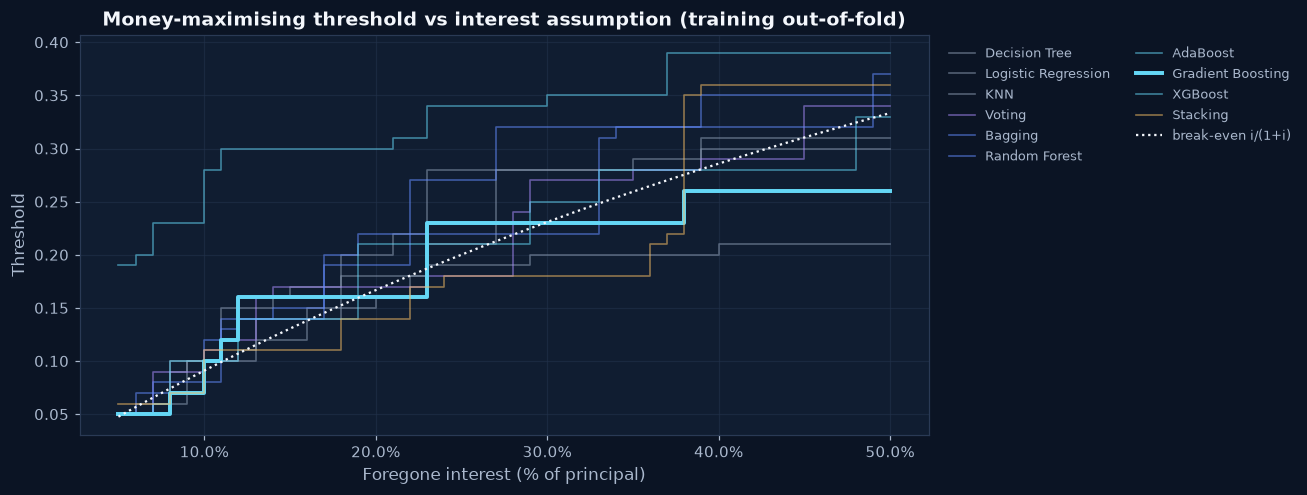

,5%,10%,20%,30%,40%,50%
Decision Tree,0.05,0.10,0.20,0.28,0.30,0.30
Logistic Regression,0.05,0.10,0.18,0.28,0.31,0.31
KNN,0.05,0.10,0.16,0.20,0.21,0.21
Voting,0.05,0.11,0.17,0.27,0.29,0.34
Bagging,0.05,0.08,0.19,0.32,0.32,0.37
Random Forest,0.05,0.12,0.22,0.22,0.35,0.35
AdaBoost,0.19,0.28,0.30,0.35,0.39,0.39
Gradient Boosting,0.05,0.10,0.16,0.23,0.26,0.26
XGBoost,0.05,0.10,0.21,0.25,0.28,0.33
Stacking,0.06,0.11,0.14,0.18,0.36,0.36


In [29]:
CURVES = T.threshold_curves(split, OOF, cvs)          # asserts equality with the official search at 20 %
grid_i = np.round(np.arange(0.05, 0.501, 0.01), 2)
thr_tab = pd.DataFrame({n: [F.threshold_at(c, i) for i in grid_i] for n, c in CURVES.items()}, index=grid_i)
fig, ax = plt.subplots(figsize=(12, 4.6))
for n in thr_tab:
    ax.step(thr_tab.index, thr_tab[n], where="post", lw=2.6 if n == DEPLOYED else 1.1, alpha=1 if n == DEPLOYED else .55,
            color=P["cyan"] if n == DEPLOYED else C.FAMILY_COLOR[C.FAMILY[n]], label=n)
ax.plot(grid_i, [F.break_even_threshold(i) for i in grid_i], ":", color=P["t1"], label="break-even i/(1+i)")
ax.set(title="Money-maximising threshold vs interest assumption (training out-of-fold)", xlabel="Foregone interest (% of principal)",
       ylabel="Threshold"); ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
ax.legend(ncol=2, fontsize=8.5, bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()
display(thr_tab.loc[[0.05, 0.10, 0.20, 0.30, 0.40, 0.50]].T.rename(columns=lambda c: f"{c:.0%}").style.format("{:.2f}")
        .set_caption("Business threshold by interest assumption"))

Thresholds rise with the interest assumption — rejecting a good customer costs more, so a model should only reject
when it is more confident — and they track the break-even line, which is what a sensible money-maximising rule should do.

<a id="s17b"></a>

### 17b. How stable is the deployment threshold?
Still training data only: the deployed model's out-of-fold money, recall, precision and false-rejection rate across
every candidate cut-off, the band of thresholds within 1 % / 2 % of the maximum, and the cut-off each of the five
inner folds would prefer on its own.

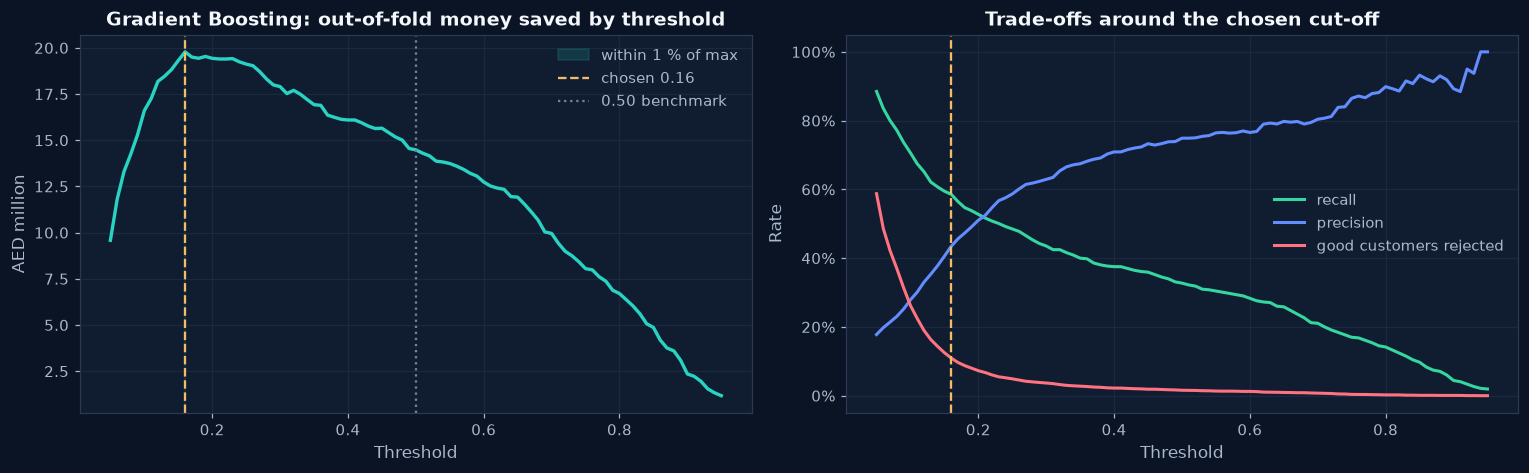

Chosen 0.16; 99 % band 0.16–0.16; 98 % band 0.16–0.23


fold,best_threshold,money_at_best,money_at_chosen
1,0.17,"AED 4,079,140","AED 3,994,440"
2,0.19,"AED 3,975,040","AED 3,893,360"
3,0.16,"AED 4,545,800","AED 4,545,800"
4,0.16,"AED 3,482,020","AED 3,482,020"
5,0.23,"AED 3,977,440","AED 3,866,820"


At 0.50 the same out-of-fold scores keep only 73% of the maximum money saved.


In [30]:
TD = T.threshold_diagnostics(split, OOF[DEPLOYED], float(cvs.set_index("model").loc[DEPLOYED, "business_threshold"]))
cur = TD["curve"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].plot(cur.threshold, cur.money_saved / 1e6, color=P["teal"], lw=2.2)
ax[0].axvspan(*TD["band_99"], color=P["teal"], alpha=.15, label="within 1 % of max")
ax[0].axvline(TD["chosen"], color=P["amber"], ls="--", label=f"chosen {TD['chosen']:.2f}")
ax[0].axvline(0.5, color=P["t3"], ls=":", label="0.50 benchmark")
ax[0].set(title=f"{DEPLOYED}: out-of-fold money saved by threshold", xlabel="Threshold", ylabel="AED million"); ax[0].legend()
for col, c, lab in [("recall", GOOD, "recall"), ("precision", P["blue"], "precision"), ("false_rejection_rate", BAD, "good customers rejected")]:
    ax[1].plot(cur.threshold, cur[col], color=c, lw=2, label=lab)
ax[1].axvline(TD["chosen"], color=P["amber"], ls="--")
ax[1].set(title="Trade-offs around the chosen cut-off", xlabel="Threshold", ylabel="Rate"); ax[1].legend()
ax[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); plt.tight_layout(); plt.show()
print(f"Chosen {TD['chosen']:.2f}; 99 % band {TD['band_99'][0]:.2f}–{TD['band_99'][1]:.2f}; 98 % band {TD['band_98'][0]:.2f}–{TD['band_98'][1]:.2f}")
display(TD["per_fold"].style.format({"best_threshold": "{:.2f}", "money_at_best": "AED {:,.0f}", "money_at_chosen": "AED {:,.0f}"}).hide(axis="index"))
share_050 = cur.set_index("threshold").loc[0.50, "money_saved"] / TD["max_money"]
print(f"At 0.50 the same out-of-fold scores keep only {share_050:.0%} of the maximum money saved.")

**Reading it.** The peak is sharp at the top (the 1 % band is narrow) but the curve stays within about 2 % of the
maximum over a wider band of cut-offs, and every inner fold prefers a threshold far below 0.50. The decision that
matters is moving away from 0.50; the second decimal moves the result by a few percent at most.

<a id="s17c"></a>

### 17c. Nested cross-validation — evaluation B
Section 17a picks the deployment model *and* its threshold on the same out-of-fold scores, so its winning figure is
optimistic. Nested CV measures the **whole procedure** without that optimism: the 4,500 training loans are split into
5 outer folds (`StratifiedKFold`, shuffled, seed 2). For each outer fold, `T.select_deployment` — the same function
that made the choice above — runs on the outer-training part only: feature selection, tuning, inner 5-fold
out-of-fold scores (seed 1), business thresholds and the model choice. The chosen pipeline is refitted on the
outer-training part and scored once on the outer-validation part at its inner threshold. The official holdout is not
touched. All ten inner-tuned models are also scored on each outer-validation part, to see whether a model the rule
picks less often is materially better.

*Computational compromise:* the hyperparameter grids, five inner folds and the 0.01 threshold grid are exactly those
of the final selection; only the number of outer folds (5) limits the cost (about 20 minutes on 2 CPU cores).

In [31]:
NESTED = T.nested_cv(split, verbose=True)
NS, NF = NESTED["summary"], NESTED["folds"]
display(NF[["fold", "model", "features", "threshold", "inner_cv_money_per_1000", "money_saved", "money_per_1000", "accuracy",
            "recall", "precision", "f1", "false_rejection_rate", "runner_up"]]
        .style.format({"threshold": "{:.2f}", "inner_cv_money_per_1000": "{:,.0f}", "money_saved": "AED {:,.0f}", "money_per_1000": "{:,.0f}",
                       "accuracy": "{:.2%}", "recall": "{:.2%}", "precision": "{:.2%}", "f1": "{:.3f}", "false_rejection_rate": "{:.2%}"})
        .hide(axis="index").set_caption("Selected model per outer fold, scored on its untouched outer-validation part"))
display(NESTED["per_model_summary"].style.format({c: "{:,.0f}" for c in ["mean_money_per_1000", "sd_money_per_1000", "mean_inner_cv_per_1000"]}
        | {c: "{:.2%}" for c in ["mean_recall", "mean_precision", "mean_accuracy"]} | {"mean_threshold": "{:.2f}", "sd_threshold": "{:.2f}"})
        .set_caption("Every candidate inside the same outer folds (each at its own inner threshold)"))
print("Selection counts:", NS["selection_counts"])
print(f"Procedure estimate: AED {NS['procedure_mean_money_per_1000']:,.0f} per 1,000 loans (sd {NS['procedure_sd_money_per_1000']:,.0f}); "
      f"inner CV said {NS['procedure_mean_inner_cv_per_1000']:,.0f} -> optimism {NS['optimism_per_1000']:,.0f} per 1,000")
print(f"Thresholds {NS['threshold_min']:.2f}-{NS['threshold_max']:.2f}; mean recall {NS['procedure_mean_recall']:.1%}, "
      f"precision {NS['procedure_mean_precision']:.1%}, good customers rejected {NS['procedure_mean_false_rejection']:.1%}")
# Is a model the rule picks less often materially better? Paired by outer fold, relative to the deployed model.
W_ = NESTED["per_model"].pivot(index="fold", columns="model", values="money_per_1000")
GAP = W_.sub(W_[DEPLOYED], axis=0).agg(["mean", "std"]).T
GAP["t"] = GAP["mean"] / (GAP["std"] / np.sqrt(len(W_)))
display(GAP.drop(index=DEPLOYED).sort_values("mean", ascending=False).style.format({"mean": "{:+,.0f}", "std": "{:,.0f}", "t": "{:+.1f}"})
        .set_caption(f"Outer-fold money per 1,000 loans: each model minus {DEPLOYED} (paired)"))
best_alt = GAP.drop(index=DEPLOYED)["mean"].idxmax()
print(f"Best alternative: {best_alt}, {GAP.loc[best_alt, 'mean']:+,.0f} per 1,000 (sd {GAP.loc[best_alt, 'std']:,.0f}, "
      f"t = {GAP.loc[best_alt, 't']:+.1f}) ->", "materially better" if GAP.loc[best_alt, "t"] >= 2 else f"not materially better; {DEPLOYED} retained")

[21:18:11]   nested fold 1/5: selected XGBoost @ 0.24 -> outer-val AED 3,810,120 (4,233,467 per 1,000 loans)  [283s]


[21:21:43]   nested fold 2/5: selected Gradient Boosting @ 0.16 -> outer-val AED 3,517,120 (3,907,911 per 1,000 loans)  [494s]


[21:25:26]   nested fold 3/5: selected Random Forest @ 0.17 -> outer-val AED 3,742,980 (4,158,867 per 1,000 loans)  [717s]


[21:30:38]   nested fold 4/5: selected Gradient Boosting @ 0.19 -> outer-val AED 3,428,240 (3,809,156 per 1,000 loans)  [1029s]


[21:35:32]   nested fold 5/5: selected Gradient Boosting @ 0.20 -> outer-val AED 4,103,760 (4,559,733 per 1,000 loans)  [1323s]


fold,model,features,threshold,inner_cv_money_per_1000,money_saved,money_per_1000,accuracy,recall,precision,f1,false_rejection_rate,runner_up
1,XGBoost,"monthly_principal_burden, annual_principal_burden_ratio, log_annual_income, has_past_default, employment_share_of_adult_life",0.24,"4,328,028","AED 3,810,120","4,233,467",88.89%,47.79%,56.84%,0.519,5.21%,AdaBoost
2,Gradient Boosting,has_past_default,0.16,"4,480,083","AED 3,517,120","3,907,911",86.11%,51.33%,45.31%,0.481,8.89%,XGBoost
3,Random Forest,has_past_default,0.17,"4,468,122","AED 3,742,980","4,158,867",83.44%,53.98%,38.61%,0.450,12.33%,XGBoost
4,Gradient Boosting,"annual_principal_burden_ratio, credit_history_years, has_past_default, employment_share_of_adult_life",0.19,"4,539,439","AED 3,428,240","3,809,156",84.56%,51.33%,40.85%,0.455,10.67%,XGBoost
5,Gradient Boosting,"annual_principal_burden_ratio, credit_history_years, log_annual_income, has_past_default",0.20,"4,262,617","AED 4,103,760","4,559,733",87.56%,59.29%,50.38%,0.545,8.39%,Stacking


,mean_money_per_1000,sd_money_per_1000,mean_inner_cv_per_1000,mean_recall,mean_precision,mean_accuracy,mean_threshold,sd_threshold,times_selected
model,,,,,,,,,
Random Forest,"4,170,240","340,842","4,353,087",53.98%,45.11%,85.78%,0.19,0.01,1
Voting,"4,168,942","364,981","4,257,838",56.99%,41.50%,83.87%,0.17,0.02,0
AdaBoost,"4,159,956","393,762","4,247,967",51.86%,48.57%,86.62%,0.34,0.04,0
XGBoost,"4,157,133","388,900","4,363,034",54.51%,45.00%,85.56%,0.18,0.04,1
Gradient Boosting,"4,135,813","326,452","4,383,967",52.04%,46.56%,86.24%,0.18,0.02,3
Logistic Regression,"4,103,391","522,103","4,151,284",58.41%,37.64%,82.49%,0.19,0.01,0
Stacking,"4,091,062","505,677","4,325,569",54.69%,44.06%,84.78%,0.14,0.02,0
Bagging,"4,015,516","452,974","4,221,944",49.73%,51.24%,86.89%,0.22,0.04,0
Decision Tree,"3,971,444","368,587","4,154,084",50.27%,47.80%,86.53%,0.20,0.03,0


Selection counts: {'Gradient Boosting': 3, 'XGBoost': 1, 'Random Forest': 1}
Procedure estimate: AED 4,133,827 per 1,000 loans (sd 295,127); inner CV said 4,415,658 -> optimism 281,831 per 1,000
Thresholds 0.16-0.24; mean recall 52.7%, precision 46.4%, good customers rejected 9.1%


,mean,std,t
model,,,
Random Forest,"+34,427","190,749",+0.4
Voting,"+33,129","294,393",+0.3
AdaBoost,"+24,142","138,408",+0.4
XGBoost,"+21,320","214,908",+0.2
Logistic Regression,"-32,422","328,938",-0.2
Stacking,"-44,751","334,047",-0.3
Bagging,"-120,298","273,663",-1.0
Decision Tree,"-164,369","237,724",-1.5
KNN,"-230,031","403,069",-1.3


Best alternative: Random Forest, +34,427 per 1,000 (sd 190,749, t = +0.4) -> not materially better; Gradient Boosting retained


**Reading it.** The table shows how often the rule lands on each model, how far the selected model's thresholds move,
and what the procedure really earns on rows it never saw — the honest figure to quote for the deployment *process*. The
per-model table checks the rule is not leaving money on the table: if a model chosen less often were materially better
on the outer folds, the rule would need revisiting. The final deployment choice is the same procedure re-run on all
4,500 training loans (Section 17a); nested CV assesses it, it does not pick it.

<a id="s17d"></a>

### 17d. Final fit and the one-time holdout evaluation (evaluation C)

In [32]:
FITTED = T.fit_all(split, TUNED, verbose=False)
RES = T.holdout_results(split, FITTED, cvs)
print("predict() agrees with 0.50 threshold on predict_proba:", {n: round(r["predict_agreement"], 4) for n, r in RES.items()})
y, loan = split.y_test.to_numpy(), split.loan_test
metrics = pd.DataFrame([E.full_row(n, r["family"], y, r["pred_050"], r["scores"], loan, 0.20) for n, r in RES.items()]).set_index("model")
display(metrics[["family", "accuracy", "recall", "precision", "f1", "specificity", "balanced_accuracy", "roc_auc", "pr_auc", "brier"]]
        .style.format({c: "{:.2%}" for c in ["accuracy", "recall", "precision", "specificity", "balanced_accuracy"]} | {"f1": "{:.3f}", "roc_auc": "{:.3f}", "pr_auc": "{:.3f}", "brier": "{:.4f}"}))

predict() agrees with 0.50 threshold on predict_proba: {'Decision Tree': 1.0, 'Logistic Regression': 1.0, 'KNN': 1.0, 'Voting': 1.0, 'Bagging': 1.0, 'Random Forest': 1.0, 'AdaBoost': 1.0, 'Gradient Boosting': 1.0, 'XGBoost': 1.0, 'Stacking': 1.0}


,family,accuracy,recall,precision,f1,specificity,balanced_accuracy,roc_auc,pr_auc,brier
model,,,,,,,,,,
Decision Tree,Single,89.53%,33.51%,66.32%,0.445,97.56%,65.54%,0.737,0.440,0.0885
Logistic Regression,Single,89.00%,20.21%,71.70%,0.315,98.86%,59.53%,0.785,0.458,0.0878
KNN,Single,88.87%,15.96%,76.92%,0.264,99.31%,57.64%,0.782,0.471,0.0886
Voting,Voting,89.47%,25.53%,72.73%,0.378,98.63%,62.08%,0.787,0.486,0.0853
Bagging,Bagging,89.80%,33.51%,69.23%,0.452,97.87%,65.69%,0.765,0.479,0.0860
Random Forest,Bagging,89.40%,29.79%,67.47%,0.413,97.94%,63.86%,0.778,0.488,0.0852
AdaBoost,Boosting,89.67%,29.79%,70.89%,0.419,98.25%,64.02%,0.803,0.507,0.1015
Gradient Boosting,Boosting,89.73%,31.91%,69.77%,0.438,98.02%,64.97%,0.804,0.491,0.0838
XGBoost,Boosting,89.80%,32.98%,69.66%,0.448,97.94%,65.46%,0.799,0.499,0.0836


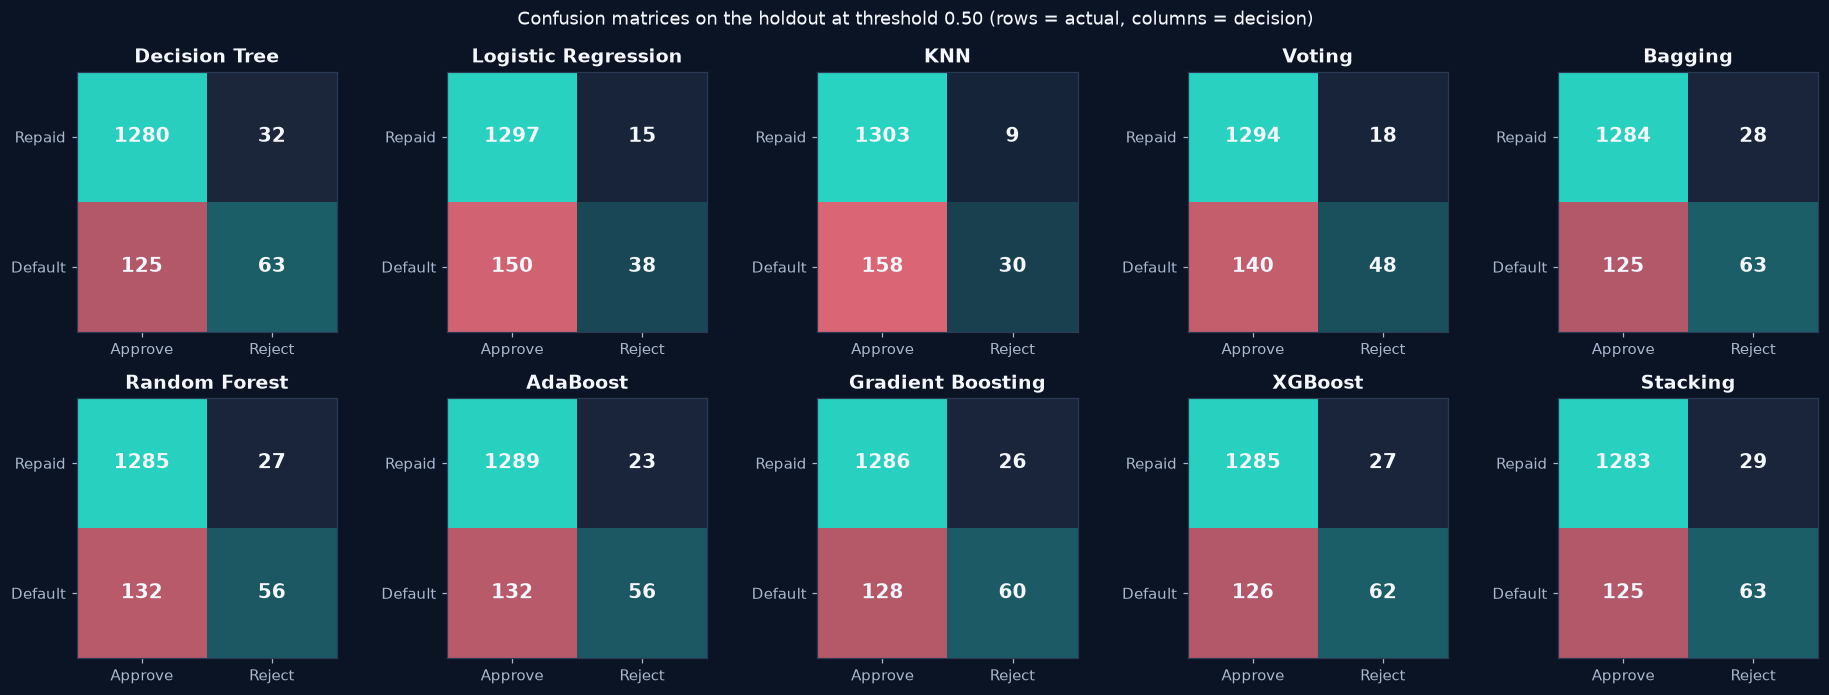

In [33]:
fig, axes = plt.subplots(2, 5, figsize=(17, 6.4))
for a, (n, r) in zip(axes.ravel(), metrics.iterrows()):
    cm = np.array([[r.tn, r.fp], [r.fn, r.tp]])
    a.imshow(np.array([[1, -1], [-1, 1]]) * cm / cm.sum(1, keepdims=True), cmap=mpl.colors.LinearSegmentedColormap.from_list("c", [BAD, P["bg3"], P["teal"]]), vmin=-1, vmax=1)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]}", ha="center", va="center", color=P["t1"], fontsize=13, fontweight="bold")
    a.set(title=n, xticks=[0, 1], yticks=[0, 1], xticklabels=["Approve", "Reject"], yticklabels=["Repaid", "Default"]); a.grid(False)
fig.suptitle("Confusion matrices on the holdout at threshold 0.50 (rows = actual, columns = decision)", color=P["t1"]); plt.tight_layout(); plt.show()

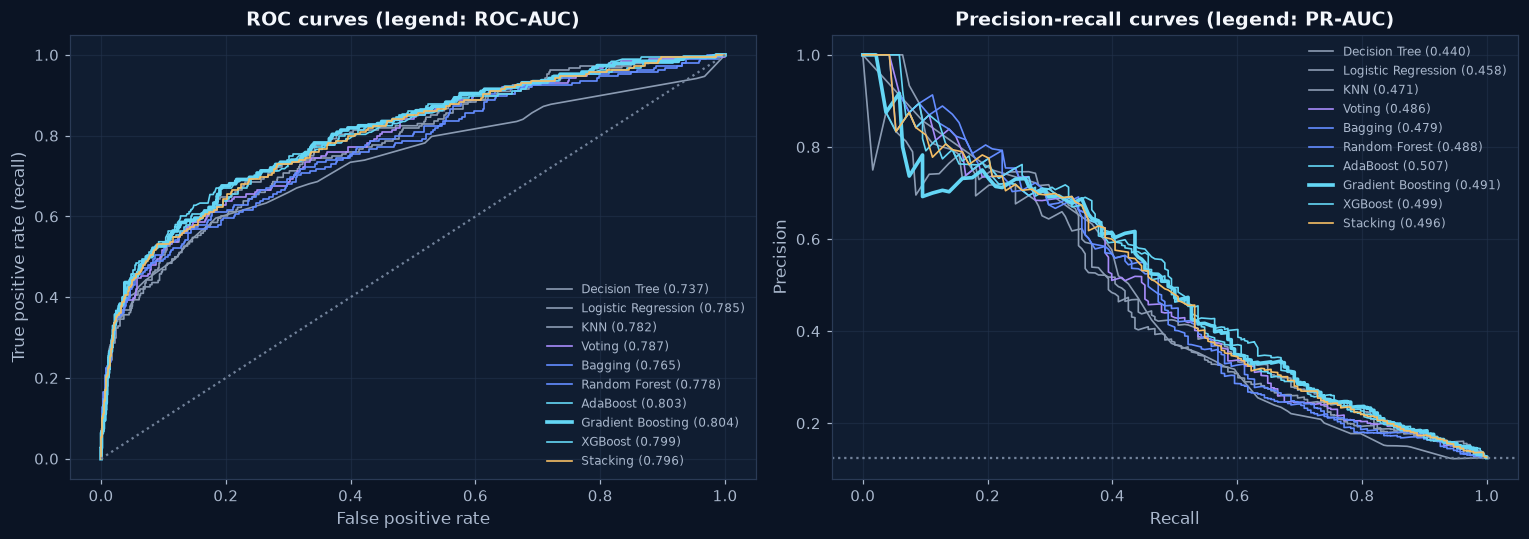

In [34]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for n, r in RES.items():
    c = r["curves"]; lw = 2.4 if n == DEPLOYED else 1.1
    ax[0].plot(c["roc"]["fpr"], c["roc"]["tpr"], lw=lw, label=f"{n} ({metrics.loc[n, 'roc_auc']:.3f})", color=C.FAMILY_COLOR[r["family"]] if n != DEPLOYED else P["cyan"])
    ax[1].plot(c["pr"]["recall"], c["pr"]["precision"], lw=lw, label=f"{n} ({metrics.loc[n, 'pr_auc']:.3f})", color=C.FAMILY_COLOR[r["family"]] if n != DEPLOYED else P["cyan"])
ax[0].plot([0, 1], [0, 1], ":", color=P["t3"]); ax[1].axhline(y.mean(), ls=":", color=P["t3"])
ax[0].set(title="ROC curves (legend: ROC-AUC)", xlabel="False positive rate", ylabel="True positive rate (recall)")
ax[1].set(title="Precision-recall curves (legend: PR-AUC)", xlabel="Recall", ylabel="Precision")
for a in ax: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

<a id="s18"></a>

## 18. Financial calculations
The official function (logic unchanged from the brief) and its decomposition. *Missed-default principal* is a separate
risk-exposure measure and is **not** subtracted a second time.

In [35]:
import inspect; print(inspect.getsource(F.money_saved))
# hand-checked example: +10,000 caught, -10,000 (0.2 × 50,000) wrongly rejected, +5,000 caught -> 5,000
assert F.money_saved([1, 1, 0, 0, 1], [1, 0, 1, 0, 1], [10_000, 20_000, 50_000, 30_000, 5_000]) == 5_000
base = F.baselines(y, loan, 0.20)
print({k: f"AED {v:,.0f}" for k, v in base.items()})

def money_saved(y_true, y_pred, loan_amounts, interest=0.20):
    """Official assignment metric (logic unchanged)."""
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    loan = np.asarray(loan_amounts)

    caught_defaulter = (y_pred == 1) & (y_true == 1)
    wrongly_rejected = (y_pred == 1) & (y_true == 0)

    return (
        loan[caught_defaulter].sum()
        - interest * loan[wrongly_rejected].sum()
    )

{'approve_all': 'AED 0', 'reject_all': 'AED -317,100', 'total_default_principal': 'AED 12,271,900', 'total_good_principal': 'AED 62,945,000'}


In [36]:
fin = pd.DataFrame([{"model": n, **F.breakdown(y, r["pred_050"], loan, 0.20)} for n, r in RES.items()]).set_index("model")
display(fin[["n_tp", "loans_saved", "n_fp", "interest_lost", "net_money_saved", "n_fn", "missed_default_principal"]]
        .sort_values("net_money_saved", ascending=False).style.format({c: "AED {:,.0f}" for c in ["loans_saved", "interest_lost", "net_money_saved", "missed_default_principal"]}))

,n_tp,loans_saved,n_fp,interest_lost,net_money_saved,n_fn,missed_default_principal
model,,,,,,,
Stacking,63,"AED 5,362,800",29,"AED 471,400","AED 4,891,400",125,"AED 6,909,100"
Decision Tree,63,"AED 5,342,800",32,"AED 534,620","AED 4,808,180",125,"AED 6,929,100"
Bagging,63,"AED 5,248,500",28,"AED 456,500","AED 4,792,000",125,"AED 7,023,400"
Gradient Boosting,60,"AED 5,133,500",26,"AED 433,240","AED 4,700,260",128,"AED 7,138,400"
XGBoost,62,"AED 5,137,800",27,"AED 446,180","AED 4,691,620",126,"AED 7,134,100"
AdaBoost,56,"AED 4,727,200",23,"AED 362,920","AED 4,364,280",132,"AED 7,544,700"
Random Forest,56,"AED 4,742,300",27,"AED 438,520","AED 4,303,780",132,"AED 7,529,600"
Voting,48,"AED 4,245,000",18,"AED 317,780","AED 3,927,220",140,"AED 8,026,900"
Logistic Regression,38,"AED 3,586,600",15,"AED 278,380","AED 3,308,220",150,"AED 8,685,300"


<a id="s19"></a>

## 19. The leaderboard 🏆 (holdout · threshold 0.50 · interest 20 %)
The same extension stage `train_models.py` runs (`T.extend`) adds the weak-learner baseline, paired bootstrap
intervals, the interest-dependent threshold curves, the no-age fairness variants and the calibration study.

*Reading the champion.* The champion is selected using the common holdout benchmark for assignment comparison. Its
reported result is a model-ranking outcome, not an independent estimate of deployment performance: picking the best
of ten scores on the same 1,500 loans favours whichever model happened to fit this sample best. The deployment
model's figure (§17d) and the nested-CV estimate (§17c) are the deployment-performance evidence.

In [37]:
LB = T.leaderboard(split, RES)
LB_BIZ = T.leaderboard(split, RES, which="pred_business")
CHAMPION = LB.iloc[0]["model"]
RUN = {"df": df, "audit": audit, "split": split, "split_check": check, "features": FEATURES, "fe_table": fe_table,
       "tuned": TUNED, "params": PARAMS, "tuning_table": tuning_table, "cw_table": cw_table, "oof": OOF, "cv_summary": cvs,
       "fitted": FITTED, "results": RES, "leaderboard": LB, "leaderboard_business": LB_BIZ, "deployed": DEPLOYED,
       "champion": CHAMPION, "data_path": str(D.resolve_data_path())}
T.extend(RUN, verbose=False)
RUN["nested_cv"] = NESTED                                 # evaluation B from §17c, exported with the artifacts
assert RUN["threshold_diagnostics"]["chosen"] == TD["chosen"]
LB = RUN["leaderboard"]                                   # now with bootstrap columns
show = LB[["rank", "model", "family", "accuracy", "recall", "precision", "f1", "tp", "fp", "money_saved",
           "money_ci_low", "money_ci_high", "p_best", "distinguishable"]]
display(show.style.format({"accuracy": "{:.2%}", "recall": "{:.2%}", "precision": "{:.2%}", "f1": "{:.3f}", "p_best": "{:.1%}",
        "money_saved": "AED {:,.0f}", "money_ci_low": "{:,.0f}", "money_ci_high": "{:,.0f}"})
        .background_gradient(subset=["money_saved"], cmap="Greens").hide(axis="index"))
acc_spread = LB.accuracy.max() - LB.accuracy.min(); money_spread = LB.money_saved.max() - LB.money_saved.min()
print(f"Accuracy spread: {acc_spread*100:.2f} points | Money-saved spread: AED {money_spread:,.0f}")

rank,model,family,accuracy,recall,precision,f1,tp,fp,money_saved,money_ci_low,money_ci_high,p_best,distinguishable
1,Stacking,Stacking,89.73%,33.51%,68.48%,0.450,63,29,"AED 4,891,400","3,635,462","6,330,138",44.4%,False
2,Decision Tree,Single,89.53%,33.51%,66.32%,0.445,63,32,"AED 4,808,180","3,559,826","6,224,408",33.7%,False
3,Bagging,Bagging,89.80%,33.51%,69.23%,0.452,63,28,"AED 4,792,000","3,563,106","6,163,396",13.6%,False
4,Gradient Boosting,Boosting,89.73%,31.91%,69.77%,0.438,60,26,"AED 4,700,260","3,497,419","6,104,572",4.0%,False
5,XGBoost,Boosting,89.80%,32.98%,69.66%,0.448,62,27,"AED 4,691,620","3,491,400","6,031,032",4.3%,False
6,AdaBoost,Boosting,89.67%,29.79%,70.89%,0.419,56,23,"AED 4,364,280","3,205,042","5,709,094",0.1%,True
7,Random Forest,Bagging,89.40%,29.79%,67.47%,0.413,56,27,"AED 4,303,780","3,127,508","5,672,044",0.0%,True
8,Voting,Voting,89.47%,25.53%,72.73%,0.378,48,18,"AED 3,927,220","2,835,304","5,230,268",0.0%,True
9,Logistic Regression,Single,89.00%,20.21%,71.70%,0.315,38,15,"AED 3,308,220","2,243,330","4,496,194",0.0%,True
10,KNN,Single,88.87%,15.96%,76.92%,0.264,30,9,"AED 2,634,960","1,704,139","3,706,292",0.0%,True


Accuracy spread: 0.93 points | Money-saved spread: AED 2,256,440


<a id="s19a"></a>

### 19a. The weak-learner baseline (brief Step 2 — shown beside, not inside, the ten)

In [38]:
(bname, bl), = RUN["baselines"].items()
brow = E.full_row(bname, "Baseline", y, bl["pred_050"], bl["scores"], loan, 0.20)
dt = LB.set_index("model").loc["Decision Tree"]
cols_ = ["accuracy", "recall", "precision", "tp", "fp", "money_saved"]
display(pd.DataFrame([{"model": bname, **{k: brow[k] for k in cols_}},
                      {"model": "Decision Tree (tuned)", **{k: dt[k] for k in cols_}}])
        .style.format({"accuracy": "{:.2%}", "recall": "{:.2%}", "precision": "{:.2%}", "money_saved": "AED {:,.0f}"}).hide(axis="index"))
print(f"Tuning the tree is worth AED {dt.money_saved - brow['money_saved']:,.0f}; the best ensemble adds a further "
      f"AED {LB.money_saved.max() - dt.money_saved:,.0f} on this holdout.")

model,accuracy,recall,precision,tp,fp,money_saved
"Shallow tree (depth 3, untuned)",89.47%,27.66%,70.27%,52,22,"AED 3,926,160"
Decision Tree (tuned),89.53%,33.51%,66.32%,63,32,"AED 4,808,180"


Tuning the tree is worth AED 882,020; the best ensemble adds a further AED 83,220 on this holdout.


<a id="s19b"></a>

### 19b. Leaderboard charts

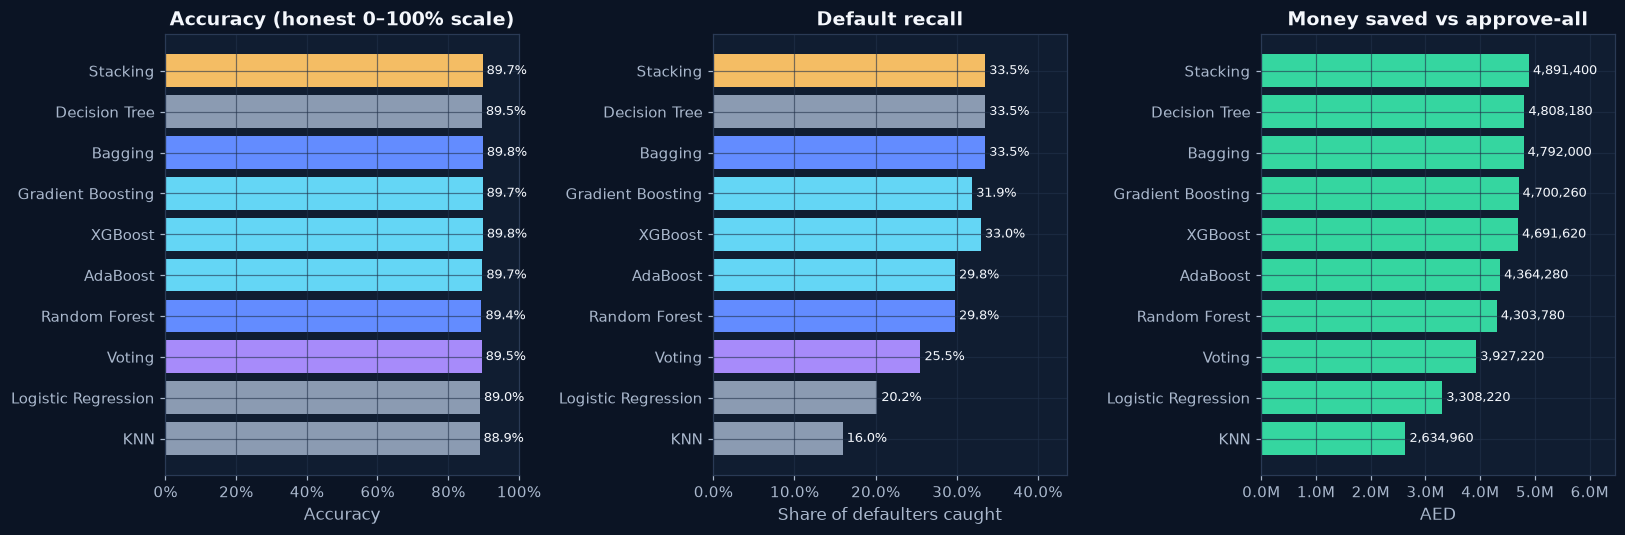

In [39]:
order = LB.sort_values("money_saved")
cols = [C.FAMILY_COLOR[f] for f in order.family]
fig, ax = plt.subplots(1, 3, figsize=(17, 5.2), gridspec_kw=dict(wspace=.55))
ax[0].barh(order.model, order.accuracy, color=cols); ax[0].set(xlim=(0, 1), title="Accuracy (honest 0–100% scale)", xlabel="Accuracy")
ax[1].barh(order.model, order.recall, color=cols); ax[1].set(title="Default recall", xlabel="Share of defaulters caught", xlim=(0, order.recall.max() * 1.3))
ax[2].barh(order.model, order.money_saved, color=[GOOD if v > 0 else BAD for v in order.money_saved]); ax[2].set(title="Money saved vs approve-all", xlabel="AED")
for a, col, fmt in [(ax[0], "accuracy", "{:.1%}"), (ax[1], "recall", "{:.1%}"), (ax[2], "money_saved", "{:,.0f}")]:
    for i, v in enumerate(order[col]): a.text(v, i, " " + fmt.format(v), va="center", color=P["t1"], fontsize=8.5)
    a.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1) if col != "money_saved" else mpl.ticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
ax[2].set_xlim(0, order.money_saved.max() * 1.32)
plt.show()

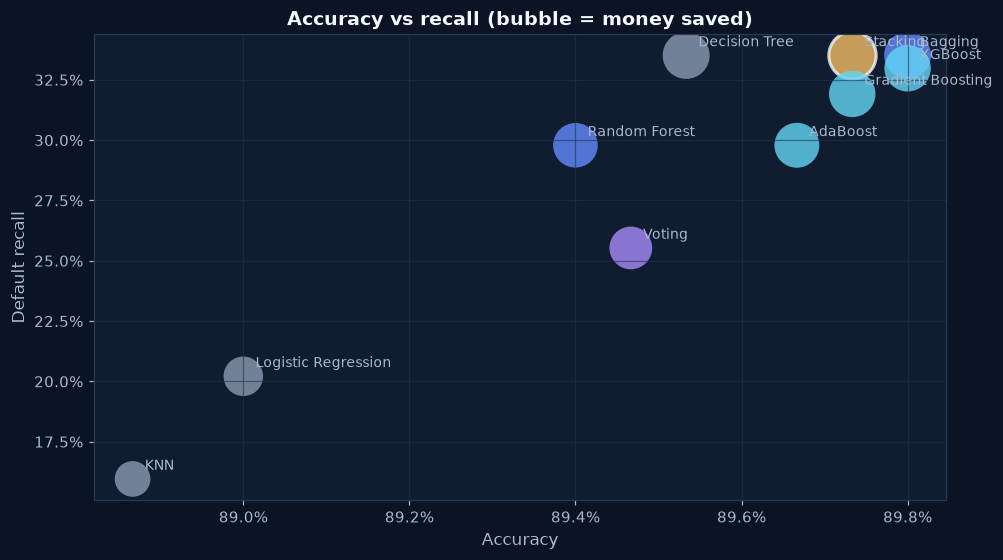

In [40]:
fig, ax = plt.subplots(figsize=(10, 5.5))
for _, r in LB.iterrows():
    ax.scatter(r.accuracy, r.recall, s=60 + 900 * max(r.money_saved, 0) / LB.money_saved.max(), color=C.FAMILY_COLOR[r.family], alpha=.8, edgecolor=P["t1"] if r["rank"] == 1 else "none", lw=2)
    ax.annotate(r.model, (r.accuracy, r.recall), textcoords="offset points", xytext=(8, 6), fontsize=9, color=P["t2"])
ax.set(title="Accuracy vs recall (bubble = money saved)", xlabel="Accuracy", ylabel="Default recall")
ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1, decimals=1)); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
plt.show()

<a id="s19c"></a>

### 19c. How certain is the ranking? — paired bootstrap of the holdout
2,000 resamples of the 1,500 test loans (with replacement); every model is scored on the *same* resample, so the gap
between two models is measured on identical loans. Models are not refitted — this isolates the uncertainty that
comes from evaluating on one finite sample.

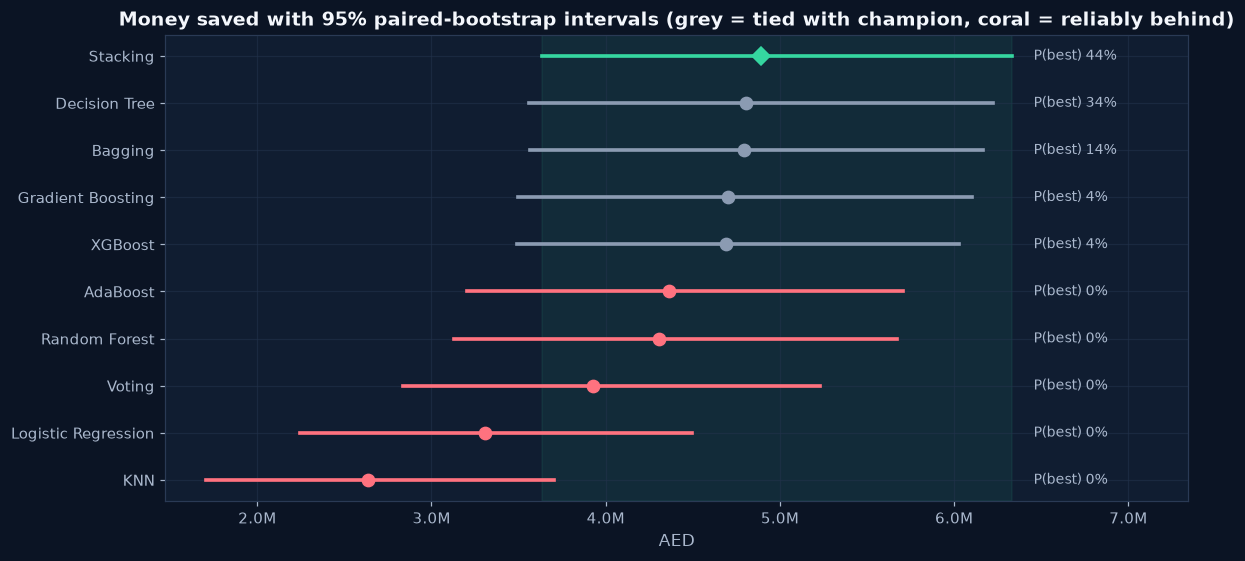

Statistically tied with Stacking (95% CI of the paired gap includes 0): ['Decision Tree', 'Bagging', 'Gradient Boosting', 'XGBoost']


In [41]:
order = LB.sort_values("money_saved")
fig, ax = plt.subplots(figsize=(11, 5.2))
ch = LB.iloc[0]
ax.axvspan(ch.money_ci_low, ch.money_ci_high, color=GOOD, alpha=.08)
for i, r in enumerate(order.itertuples()):
    col = GOOD if r.model == CHAMPION else (P["neutral"] if not r.distinguishable else BAD)
    ax.plot([r.money_ci_low, r.money_ci_high], [i, i], color=col, lw=2.4)
    ax.plot(r.money_saved, i, "D" if r.model == CHAMPION else "o", color=col, ms=8)
    ax.text(order.money_ci_high.max() * 1.02, i, f"P(best) {r.p_best:.0%}", va="center", color=P["t2"], fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order.model)
ax.set(title="Money saved with 95% paired-bootstrap intervals (grey = tied with champion, coral = reliably behind)", xlabel="AED")
ax.xaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M")); ax.set_xlim(right=order.money_ci_high.max() * 1.16)
plt.tight_layout(); plt.show()
ties = LB[(LB.model != CHAMPION) & (~LB.distinguishable)].model.tolist()
print(f"Statistically tied with {CHAMPION} (95% CI of the paired gap includes 0): {ties}")

**Reading it.** The intervals are wide (roughly ±AED 1.3M) because only 188 loans default and each defaulted loan is
worth tens of thousands of dirhams. Several top models are statistically tied with the champion; only the weaker tail
is reliably behind. The robust conclusions are therefore *which group* of models to consider and *how to set the
threshold* — not the exact order at the top.

In [42]:
display(Markdown("**Separate report — holdout at each model's CV-chosen business threshold (20 %)** (not the primary benchmark):"))
display(LB_BIZ[["rank", "model", "accuracy", "recall", "fp", "money_saved"]].assign(threshold=LB_BIZ.model.map(cvs.set_index("model").business_threshold))
        .style.format({"accuracy": "{:.2%}", "recall": "{:.2%}", "money_saved": "AED {:,.0f}", "threshold": "{:.2f}"}).hide(axis="index"))

**Separate report — holdout at each model's CV-chosen business threshold (20 %)** (not the primary benchmark):

rank,model,accuracy,recall,fp,money_saved,threshold
1,AdaBoost,86.07%,52.66%,120,"AED 6,231,400",0.30
2,XGBoost,87.33%,49.47%,95,"AED 6,047,320",0.21
3,Stacking,85.20%,53.19%,134,"AED 6,026,420",0.14
4,Logistic Regression,81.60%,59.04%,199,"AED 5,978,180",0.18
5,Gradient Boosting,84.80%,54.26%,142,"AED 5,943,420",0.16
6,Voting,83.47%,54.26%,162,"AED 5,773,900",0.17
7,Random Forest,87.00%,46.81%,95,"AED 5,706,720",0.22
8,Bagging,85.13%,48.94%,127,"AED 5,514,800",0.19
9,KNN,83.33%,49.47%,155,"AED 5,249,640",0.16
10,Decision Tree,85.40%,46.28%,118,"AED 5,097,580",0.20


<a id="s20"></a>

## 20. Comparative financial analysis
<a id="s20a"></a>

### 20a. Interest-rate sensitivity — fixed 0.50 threshold vs thresholds re-optimised per interest

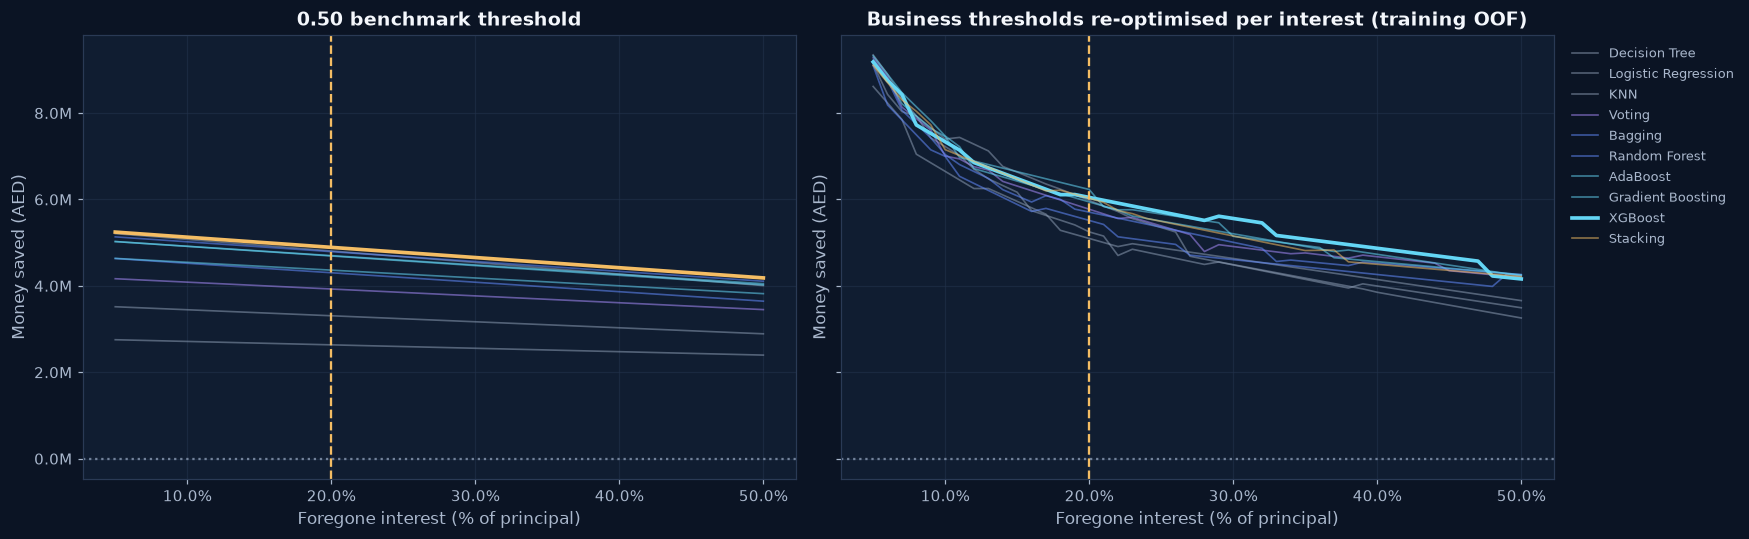

Champion by interest (0.50): 5%–50%: Stacking
Champion by interest (business): 5%–6%: KNN | 7%–10%: Gradient Boosting | 11%–14%: Logistic Regression | 15%–20%: AdaBoost | 21%–47%: XGBoost | 48%: Gradient Boosting | 49%: AdaBoost | 50%: Random Forest


In [43]:
grid = np.round(np.arange(0.05, 0.501, 0.01), 2)
sens = pd.DataFrame({n: [F.money_saved(y, r["pred_050"], loan, i) for i in grid] for n, r in RES.items()}, index=grid)
sens_biz = pd.DataFrame({n: [F.money_saved(y, (r["scores"] >= F.threshold_at(RUN["threshold_curves"][n], i)).astype(int), loan, i)
                             for i in grid] for n, r in RES.items()}, index=grid)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, tab, title in [(axes[0], sens, "0.50 benchmark threshold"), (axes[1], sens_biz, "Business thresholds re-optimised per interest (training OOF)")]:
    lead = tab.mean().idxmax()
    for n in tab: ax.plot(tab.index, tab[n], lw=2.4 if n == lead else 1.1, color=C.FAMILY_COLOR[C.FAMILY[n]], alpha=1 if n == lead else .55, label=n)
    ax.axvline(.2, ls="--", color=P["amber"]); ax.axhline(0, ls=":", color=P["t3"])
    ax.set(title=title, xlabel="Foregone interest (% of principal)", ylabel="Money saved (AED)")
    ax.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1)); ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
axes[1].legend(ncol=1, fontsize=8.5, bbox_to_anchor=(1.01, 1), loc="upper left"); plt.tight_layout(); plt.show()
for label, tab in [("0.50", sens), ("business", sens_biz)]:
    champ = tab.idxmax(axis=1)
    print(f"Champion by interest ({label}):", " | ".join(champ.groupby((champ != champ.shift()).cumsum())
          .agg(lambda s: (f"{s.index.min():.0%}" if s.index.min() == s.index.max() else f"{s.index.min():.0%}–{s.index.max():.0%}") + f": {s.iloc[0]}")))

<a id="s20b"></a>

### 20b. Instructor benchmark comparison (same split, independent models — not adjusted to match)

In [44]:
ref = pd.DataFrame(C.REFERENCE_RESULTS).T.rename(columns={"acc": "ref_accuracy", "recall": "ref_recall", "money": "ref_money"})
cmp_ = LB.set_index("model")[["accuracy", "recall", "money_saved"]].join(ref)
cmp_["delta_money"] = cmp_.money_saved - cmp_.ref_money
display(cmp_.style.format({"accuracy": "{:.2%}", "ref_accuracy": "{:.2%}", "recall": "{:.2%}", "ref_recall": "{:.2%}", "money_saved": "{:,.0f}", "ref_money": "{:,.0f}", "delta_money": "{:+,.0f}"}))
print(f"Reference: best money {ref.ref_money.max():,.0f} ({ref.ref_money.idxmax()}), spread {ref.ref_money.max()-ref.ref_money.min():,.0f}")
print(f"This build: best money {LB.money_saved.max():,.0f} ({LB.model[0]}), spread {money_spread:,.0f}")

,accuracy,recall,money_saved,ref_accuracy,ref_recall,ref_money,delta_money
model,,,,,,,
Stacking,89.73%,33.51%,"4,891,400",89.40%,30.85%,"4,557,820","+333,580"
Decision Tree,89.53%,33.51%,"4,808,180",89.47%,27.66%,"3,926,160","+882,020"
Bagging,89.80%,33.51%,"4,792,000",89.67%,31.38%,"4,532,740","+259,260"
Gradient Boosting,89.73%,31.91%,"4,700,260",89.27%,32.98%,"4,685,580","+14,680"
XGBoost,89.80%,32.98%,"4,691,620",89.47%,33.51%,"4,826,940","-135,320"
AdaBoost,89.67%,29.79%,"4,364,280",89.07%,19.68%,"2,979,120","+1,385,160"
Random Forest,89.40%,29.79%,"4,303,780",89.60%,31.38%,"4,597,560","-293,780"
Voting,89.47%,25.53%,"3,927,220",89.13%,21.81%,"3,471,680","+455,540"
Logistic Regression,89.00%,20.21%,"3,308,220",88.80%,21.81%,"3,307,300",+920


Reference: best money 4,826,940 (XGBoost), spread 2,605,920
This build: best money 4,891,400 (Stacking), spread 2,256,440


**Why results differ legitimately.** The split is identical (Section 8), so differences come from configuration: this
build tunes every model by CV instead of using defaults, adds two engineered features, scales LR/KNN inputs, uses
soft voting and a stacking design of its own. Both builds reproduce the same lesson — accuracy within about one point,
money saved spread by millions — and, per Section 19c, the gap between the two champions is well inside holdout noise.

<a id="s20c"></a>

### 20c. Permutation importance (training-internal validation fold — the test set is not used)

In [45]:
PERM = T.permutation_study(split, TUNED, verbose=False)
RUN["permutation"] = PERM
imp = pd.DataFrame({n: PERM[n].set_index("feature")["importance_mean"] for n in [CHAMPION, DEPLOYED, "Logistic Regression"]})
display(imp.sort_values(imp.columns[0], ascending=False).style.format("{:+.4f}").background_gradient(cmap="Greens"))

,Stacking,Gradient Boosting,Logistic Regression
feature,,,
past_defaults,+0.0731,+0.0716,+0.0693
debt_to_income,+0.0606,+0.0893,+0.1149
annual_income,+0.0208,+0.0166,+0.0159
num_existing_loans,+0.0144,+0.0182,+0.0092
loan_amount,+0.0045,+0.0027,+0.0000
home_ownership,+0.0027,+0.0034,+0.0034
employment_years,+0.0016,-0.0001,-0.0011
credit_history_months,+0.0016,+0.0017,+0.0011
age,-0.0003,-0.0034,-0.0004


Importance is the drop in validation ROC-AUC when one raw input is shuffled. It is associative, not causal, and is
shared out between correlated inputs (loan amount, income, debt_to_income).

<a id="s20d"></a>

### 20d. Fairness check — does the model need age?
Each studied model (deployed and leaderboard champion) is rebuilt **without age** and without the age-derived
engineered feature, its business threshold is re-tuned on training OOF scores, and it is scored on the same holdout.

**Gradient Boosting**

variant,policy,threshold,accuracy,recall,roc_auc,fp,money_saved
with_age,0.50 benchmark,0.50,89.73%,31.91%,0.804,26,"AED 4,700,260"
with_age,CV business,0.16,84.80%,54.26%,0.804,142,"AED 5,943,420"
without_age,0.50 benchmark,0.50,89.80%,32.45%,0.807,26,"AED 4,763,080"
without_age,CV business,0.22,87.67%,47.87%,0.807,87,"AED 5,972,220"


**Stacking**

variant,policy,threshold,accuracy,recall,roc_auc,fp,money_saved
with_age,0.50 benchmark,0.50,89.73%,33.51%,0.796,29,"AED 4,891,400"
with_age,CV business,0.14,85.20%,53.19%,0.796,134,"AED 6,026,420"
without_age,0.50 benchmark,0.50,89.80%,34.04%,0.798,29,"AED 4,934,300"
without_age,CV business,0.17,87.40%,49.47%,0.798,94,"AED 6,069,240"


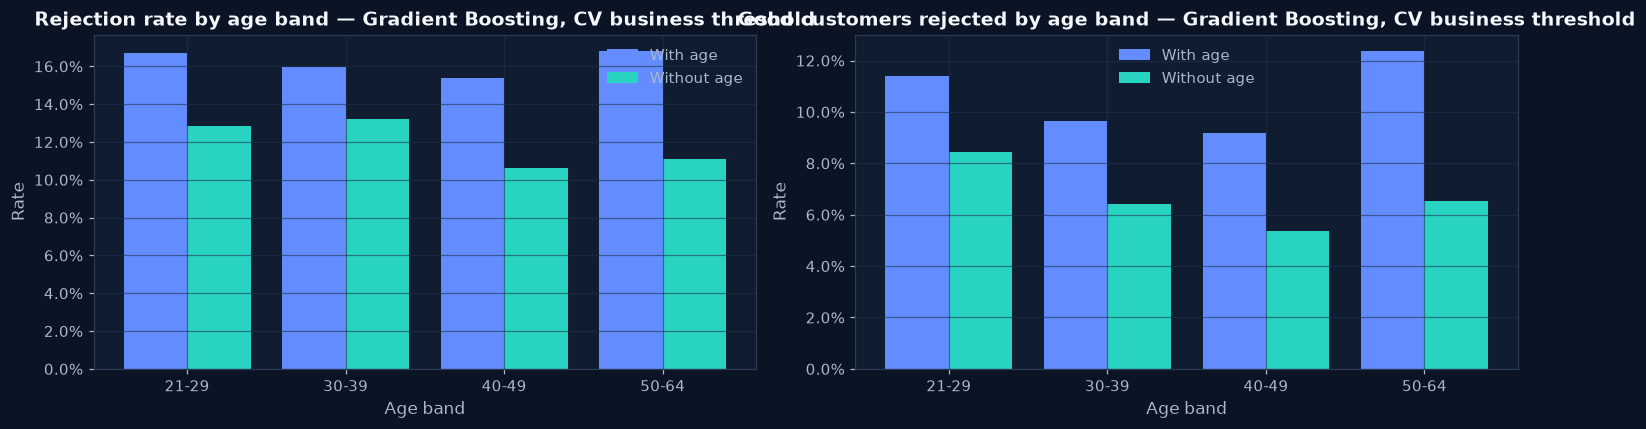

Largest |correlation| of age with any other input: 0.017
Business threshold: 0.16 with age vs 0.22 without


,change in rejection_rate (pts),change in false_rejection_rate (pts),change in recall (pts)
group,,,
21-29,-3.9,-2.9,-10.3
30-39,-2.8,-3.2,+0.0
40-49,-4.7,-3.8,-11.9
50-64,-5.7,-5.9,-4.9


In [46]:
for name, f in RUN["fairness"].items():
    display(Markdown(f"**{name}**"))
    display(f["table"][["variant", "policy", "threshold", "accuracy", "recall", "roc_auc", "fp", "money_saved"]]
            .style.format({"threshold": "{:.2f}", "accuracy": "{:.2%}", "recall": "{:.2%}", "roc_auc": "{:.3f}", "money_saved": "AED {:,.0f}"}).hide(axis="index"))
seg_ = RUN["fairness"][DEPLOYED]["segments"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, metric, title in [(ax[0], "rejection_rate", "Rejection rate by age band"), (ax[1], "false_rejection_rate", "Good customers rejected by age band")]:
    w, o = seg_[("with_age", "CV business")], seg_[("without_age", "CV business")]
    xs = np.arange(len(w)); a.bar(xs - .2, w[metric], .4, color=P["blue"], label="With age"); a.bar(xs + .2, o[metric], .4, color=P["teal"], label="Without age")
    a.set_xticks(xs); a.set_xticklabels(w["group"]); a.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1))
    a.set(title=f"{title} — {DEPLOYED}, CV business threshold", xlabel="Age band", ylabel="Rate"); a.legend()
plt.tight_layout(); plt.show()
print("Largest |correlation| of age with any other input:", df.drop(columns="home_ownership").corr()["age"].drop(["age", "default"]).abs().max().round(3))
w_, o_ = seg_[("with_age", "CV business")].set_index("group"), seg_[("without_age", "CV business")].set_index("group")
t_with = RES[DEPLOYED]["business_threshold"]; t_wo = RUN["fairness"][DEPLOYED]["threshold_without_age"]
print(f"Business threshold: {t_with:.2f} with age vs {t_wo:.2f} without")
display(((o_[["rejection_rate", "false_rejection_rate", "recall"]] - w_[["rejection_rate", "false_rejection_rate", "recall"]]) * 100)
        .round(1).rename(columns=lambda c: f"change in {c} (pts)").style.format("{:+.1f}").set_caption(f"{DEPLOYED}: without age minus with age"))

**Reading it.** Removing age costs nothing in money here — the no-age variants save slightly *more* on this holdout,
well within the bootstrap noise of Section 19c. Rejection and false-rejection rates fall by a few points in **every**
age band without age; that is mostly because the no-age model's tuned business threshold is higher (printed above), so
it rejects fewer applicants overall — a near-uniform shift rather than one that singles out an age band. In this
synthetic data age is almost uncorrelated with the other inputs, so excluding it also removes most of its indirect
influence. That supports dropping age from a production model, but it is a diagnostic, not a fairness certification:
real portfolios contain proxies, and legal and regulatory review is still required.

<a id="s20e"></a>

### 20e. Calibration of the deployed model

,training-OOF Brier,training-OOF ECE
raw,0.08016,0.01201
sigmoid,0.08002,0.01400
isotonic,0.08022,0.00810


Rule: calibrate only if training-OOF Brier AND ECE both improve (method = lower OOF Brier); otherwise keep the raw score. Show it as a probability only if its training-OOF ECE <= 2%.
Chosen calibrator by Brier: sigmoid | calibration justified: False | probability source: raw | probability display justified: True
Holdout check: {'raw_brier': 0.08377, 'cal_brier': 0.0837, 'raw_ece': 0.00632, 'cal_ece': 0.01207}


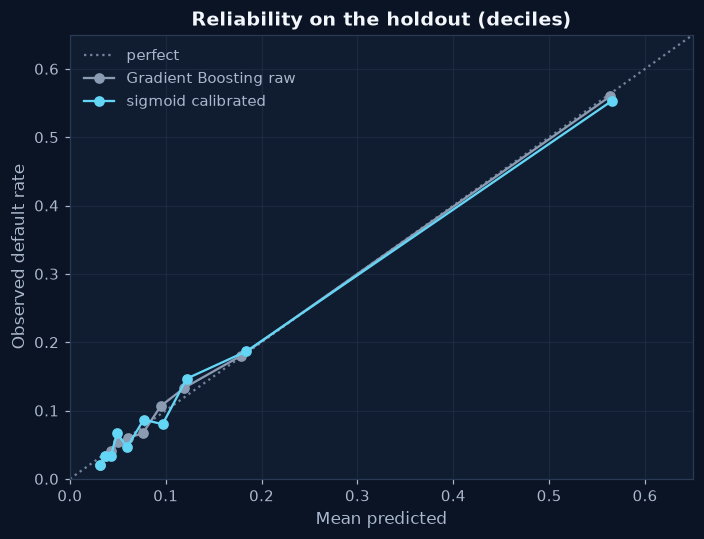

In [47]:
cal = RUN["calibration"]
display(pd.DataFrame(cal["candidates"]).T.rename(columns={"oof_brier": "training-OOF Brier", "oof_ece": "training-OOF ECE"}).style.format("{:.5f}"))
print("Rule:", cal["rule"])
print(f"Chosen calibrator by Brier: {cal['method']} | calibration justified: {cal['justified']} | probability source: "
      f"{cal['probability_source']} | probability display justified: {cal['probability_justified']}")
print("Holdout check:", {k: round(v, 5) for k, v in cal["holdout"].items()})
fig, ax = plt.subplots(figsize=(6.5, 5))
mx = 0.65
ax.plot([0, mx], [0, mx], ":", color=P["t3"], label="perfect")
ax.plot(cal["curve_raw"]["mean_pred"], cal["curve_raw"]["frac_pos"], "o-", color=P["neutral"], label=f"{DEPLOYED} raw")
ax.plot(cal["curve_cal"]["mean_pred"], cal["curve_cal"]["frac_pos"], "o-", color=P["cyan"], label=f"{cal['method']} calibrated")
ax.set(title="Reliability on the holdout (deciles)", xlabel="Mean predicted", ylabel="Observed default rate", xlim=(0, mx), ylim=(0, mx)); ax.legend()
plt.tight_layout(); plt.show()

**Reading it.** Gradient boosting with log-loss already produces well-calibrated scores, so neither calibrator improves
*both* Brier and ECE on training out-of-fold data and the raw score is kept. Because its training-OOF ECE is within
the 2-point tolerance (and the holdout confirms it), the simulator presents the deployed model's score as an
estimated probability of default; for every other model it remains a ranking score.

<a id="s20f"></a>

### 20f. Reason codes for individual decisions
Exact explanations only: Tree SHAP for tree models, coefficient × (value − training mean) for logistic regression.
Base value + contributions reproduces the model's own output, checked on every call.

In [48]:
from quickloan import explain as X
ex = X.ReasonExplainer(DEPLOYED, FITTED[DEPLOYED], split.X_train)
thr = cvs.set_index("model").loc[DEPLOYED, "business_threshold"]
s_dep = RES[DEPLOYED]["scores"]
for label, i in [("highest-risk holdout applicant", int(np.argmax(s_dep))), ("lowest-risk holdout applicant", int(np.argmin(s_dep)))]:
    e = ex.explain(split.X_test.iloc[[i]])
    reject = s_dep[i] >= thr
    display(Markdown(f"**{label}** — score {s_dep[i]:.3f} vs threshold {thr:.2f} → **{'REJECT' if reject else 'APPROVE'}** "
                     f"(additivity error {e.max_additivity_error:.1e}, units: {e.units})"))
    display(e.table.head(6).style.format({"contribution": "{:+.3f}"}).hide(axis="index"))
    print("  reason codes:", X.reason_codes(e, reject))

**highest-risk holdout applicant** — score 0.973 vs threshold 0.16 → **REJECT** (additivity error 4.4e-16, units: log-odds)

feature,label,value,contribution
debt_to_income,Loan-to-income,2.51,+3.530
past_defaults,Past defaults,1,+0.894
loan_amount,Loan amount,"AED 137,100",+0.555
has_past_default,Any past default (derived),yes,+0.544
annual_income,Annual income,"AED 54,600",+0.509
home_ownership,Home ownership,rent,+0.091


  reason codes: ['Loan-to-income = 2.51 raised the risk score', 'Past defaults = 1 raised the risk score', 'Loan amount = AED 137,100 raised the risk score']


**lowest-risk holdout applicant** — score 0.025 vs threshold 0.16 → **APPROVE** (additivity error 4.4e-16, units: log-odds)

feature,label,value,contribution
debt_to_income,Loan-to-income,0.42,-0.395
annual_income,Annual income,"AED 154,300",-0.265
age,Age,64,-0.175
past_defaults,Past defaults,0,-0.141
home_ownership,Home ownership,mortgage,-0.119
has_past_default,Any past default (derived),no,-0.102


  reason codes: ['Loan-to-income = 0.42 lowered the risk score', 'Annual income = AED 154,300 lowered the risk score', 'Age = 64 lowered the risk score']


<a id="s21"></a>

## 21. Business recommendation (generated from the numbers above)

In [49]:
L, A_ = LB.iloc[0], LB.loc[LB.accuracy.idxmax()]
dep_biz = LB_BIZ.set_index("model").loc[DEPLOYED]
ties = LB[(LB.model != CHAMPION) & (~LB.distinguishable)].model.tolist()
fair = RUN["fairness"][DEPLOYED]["table"].set_index(["variant", "policy"])["money_saved"]
age_gap = fair[("with_age", "CV business")] - fair[("without_age", "CV business")]
repaid = 1 - y.mean()
dep_thr = cvs.set_index("model").loc[DEPLOYED, "business_threshold"]
lines = [
    "**Recommendation to QuickLoan leadership.**",
    "",
    f"* **Leaderboard champion: {L.model}** — saves **AED {L.money_saved:,.0f}** on the 1,500 test loans versus approving "
    f"everyone at 20 % interest and the 0.50 threshold, catching **{int(L.tp)} of {int(y.sum())} defaulters** (recall "
    f"{L.recall:.1%}) while rejecting {int(L.fp)} good customers (AED {L.interest_lost:,.0f} of foregone interest). Accuracy "
    f"{L.accuracy:.2%}. It is saved as `loan_model_leaderboard_champion.joblib`, as the brief asks.",
    f"* **But the lead is not decisive.** Its 95% bootstrap interval is AED {L.money_ci_low:,.0f} – {L.money_ci_high:,.0f} and "
    f"it wins only **{L.p_best:.0%}** of resamples; {len(ties)} other models ({', '.join(ties)}) are statistically tied with it.",
    f"* **Accuracy would not have found it.** All ten models sit within **{acc_spread*100:.1f} accuracy points**, but money "
    f"saved ranges over **AED {money_spread:,.0f}**. The most accurate model ({A_.model}, {A_.accuracy:.2%}) saves "
    f"AED {A_.money_saved:,.0f}. With {repaid:.1%} of holdout loans repaid, accuracy mostly rewards approving good customers.",
    f"* **What to deploy — and why it differs from the champion.** The champion was chosen *using* the holdout, so its "
    f"holdout figure is optimistic. The leakage-free choice, made on training cross-validation before the holdout was "
    f"opened, is **{DEPLOYED}** with a money-maximising threshold of {dep_thr:.2f} at 20 % (`loan_model.joblib`). On the "
    f"untouched holdout that policy saves **AED {dep_biz.money_saved:,.0f}** (recall {dep_biz.recall:.1%}, {int(dep_biz.fp)} "
    f"good customers rejected) — {'more than' if dep_biz.money_saved > LB.money_saved.max() else 'compared with'} "
    f"the best model at 0.50 (AED {LB.money_saved.max():,.0f}). The threshold is the biggest money lever and is "
    f"re-optimised for other interest assumptions from the same training curves.",
    f"* **The procedure is checked, not just the winner.** Nested cross-validation (5 outer × 5 inner folds, training "
    f"data only) re-ran the whole selection {NS['outer_folds']} times: it chose "
    + ", ".join(f"{k} {v}×" for k, v in NS["selection_counts"].items()) +
    f", with thresholds {NS['threshold_min']:.2f}–{NS['threshold_max']:.2f}, and earned **AED "
    f"{NS['procedure_mean_money_per_1000']:,.0f} per 1,000 loans** on rows it never saw (sd "
    f"{NS['procedure_sd_money_per_1000']:,.0f}); the deployed policy's holdout figure is AED "
    f"{dep_biz.money_saved / len(y) * 1000:,.0f} per 1,000.",
    f"* **Age is not needed.** Without age the deployed model saves AED {abs(age_gap):,.0f} "
    f"{'less' if age_gap > 0 else 'more'} at its business threshold — inside holdout noise — so the production model "
    f"should exclude it, subject to legal review.",
    f"* **Trade-off accepted.** Higher recall costs some good customers and interpretability. Exact reason codes (Tree "
    f"SHAP) make each {DEPLOYED} decision explainable, and its raw score is already well calibrated, so it can be read "
    f"as a probability of default.",
    "* **Before production:** validate on a later time period, model recoveries and funding costs, and run full fairness, "
    "compliance and model-risk review. This is an educational model, not an approval system.",
]
display(Markdown("\n".join(lines)))

**Recommendation to QuickLoan leadership.**

* **Leaderboard champion: Stacking** — saves **AED 4,891,400** on the 1,500 test loans versus approving everyone at 20 % interest and the 0.50 threshold, catching **63 of 188 defaulters** (recall 33.5%) while rejecting 29 good customers (AED 471,400 of foregone interest). Accuracy 89.73%. It is saved as `loan_model_leaderboard_champion.joblib`, as the brief asks.
* **But the lead is not decisive.** Its 95% bootstrap interval is AED 3,635,462 – 6,330,138 and it wins only **44%** of resamples; 4 other models (Decision Tree, Bagging, Gradient Boosting, XGBoost) are statistically tied with it.
* **Accuracy would not have found it.** All ten models sit within **0.9 accuracy points**, but money saved ranges over **AED 2,256,440**. The most accurate model (Bagging, 89.80%) saves AED 4,792,000. With 87.5% of holdout loans repaid, accuracy mostly rewards approving good customers.
* **What to deploy — and why it differs from the champion.** The champion was chosen *using* the holdout, so its holdout figure is optimistic. The leakage-free choice, made on training cross-validation before the holdout was opened, is **Gradient Boosting** with a money-maximising threshold of 0.16 at 20 % (`loan_model.joblib`). On the untouched holdout that policy saves **AED 5,943,420** (recall 54.3%, 142 good customers rejected) — more than the best model at 0.50 (AED 4,891,400). The threshold is the biggest money lever and is re-optimised for other interest assumptions from the same training curves.
* **The procedure is checked, not just the winner.** Nested cross-validation (5 outer × 5 inner folds, training data only) re-ran the whole selection 5 times: it chose Gradient Boosting 3×, XGBoost 1×, Random Forest 1×, with thresholds 0.16–0.24, and earned **AED 4,133,827 per 1,000 loans** on rows it never saw (sd 295,127); the deployed policy's holdout figure is AED 3,962,280 per 1,000.
* **Age is not needed.** Without age the deployed model saves AED 28,800 more at its business threshold — inside holdout noise — so the production model should exclude it, subject to legal review.
* **Trade-off accepted.** Higher recall costs some good customers and interpretability. Exact reason codes (Tree SHAP) make each Gradient Boosting decision explainable, and its raw score is already well calibrated, so it can be read as a probability of default.
* **Before production:** validate on a later time period, model recoveries and funding costs, and run full fairness, compliance and model-risk review. This is an educational model, not an approval system.

<a id="s22"></a>

## 22. Model export
Calls `train_models.export(RUN)` — the exact function the script uses — then reloads every artifact independently.
Artifact contract: see `quickloan/artifacts.py` and the README.

In [50]:
import train_models
lb_csv, biz_csv = train_models.export(RUN)
dep, champ = A.load_model_artifact(C.MODEL_ARTIFACT), A.load_model_artifact(C.CHAMPION_ARTIFACT)
assert np.allclose(dep["pipeline"].predict_proba(split.X_test)[:, 1], RES[DEPLOYED]["scores"])
assert np.allclose(champ["pipeline"].predict_proba(split.X_test)[:, 1], RES[CHAMPION]["scores"])
evr = A.load_eval_artifact()
for name, art_ in [(C.MODEL_ARTIFACT.name, dep), (C.CHAMPION_ARTIFACT.name, champ)]:
    print(f"{name}: {art_['model_name']} · selected_on={art_['selected_on']} · business threshold @20% "
          f"{art_['thresholds']['business']:.2f} · @50% {art_['thresholds']['business_by_interest'][50]:.2f} · "
          f"probability available: {art_['score_type']['probability_available']}")
print("Evaluation artifact keys:", len(evr))
display(lb_csv[["rank", "model", "money_saved", "money_ci_low", "money_ci_high", "p_best"]].head(5))

loan_model.joblib: Gradient Boosting · selected_on=training_cv · business threshold @20% 0.16 · @50% 0.26 · probability available: True
loan_model_leaderboard_champion.joblib: Stacking · selected_on=holdout · business threshold @20% 0.14 · @50% 0.36 · probability available: False
Evaluation artifact keys: 33


,rank,model,money_saved,money_ci_low,money_ci_high,p_best
0,1,Stacking,"4,891,400.0000","3,635,461.5000","6,330,138.0000",0.4440
1,2,Decision Tree,"4,808,180.0000","3,559,826.0000","6,224,408.5000",0.3365
2,3,Bagging,"4,792,000.0000","3,563,106.0000","6,163,396.0000",0.1360
3,4,Gradient Boosting,"4,700,260.0000","3,497,418.5000","6,104,571.5000",0.0400
4,5,XGBoost,"4,691,620.0000","3,491,400.0000","6,031,031.5000",0.0430


## Summary check
Re-computes every headline figure quoted in the executive summary at the top and fails loudly if any differs.

In [51]:
H = {'champion': 'Stacking', 'champion_money': 4891400, 'acc_spread_pts': 0.9, 'money_spread': 2256440, 'p_best_pct': 44, 'n_tied': 4, 'deployed': 'Gradient Boosting', 'deployed_threshold': 0.16, 'deployed_money': 5943420, 'deployed_recall_pct': 54.3, 'age_gain': 28800, 'nested_per_1000': 4133827, 'nested_sd_per_1000': 295127, 'nested_deployed_folds': 3}
L = LB.iloc[0]
dep_row = LB_BIZ.set_index("model").loc[DEPLOYED]
fair_t = RUN["fairness"][DEPLOYED]["table"].set_index(["variant", "policy"])["money_saved"]
checks = {
    "champion": (L.model, H["champion"]),
    "champion_money": (int(round(L.money_saved)), H["champion_money"]),
    "acc_spread_pts": (round(acc_spread * 100, 1), H["acc_spread_pts"]),
    "money_spread": (int(round(money_spread)), H["money_spread"]),
    "p_best_pct": (int(round(L.p_best * 100)), H["p_best_pct"]),
    "n_tied": (int(((LB.model != L.model) & (~LB.distinguishable)).sum()), H["n_tied"]),
    "deployed": (DEPLOYED, H["deployed"]),
    "deployed_threshold": (round(float(cvs.set_index("model").loc[DEPLOYED, "business_threshold"]), 2), H["deployed_threshold"]),
    "deployed_money": (int(round(dep_row.money_saved)), H["deployed_money"]),
    "deployed_recall_pct": (round(dep_row.recall * 100, 1), H["deployed_recall_pct"]),
    "age_gain": (int(round(fair_t[("without_age", "CV business")] - fair_t[("with_age", "CV business")])), H["age_gain"]),
    "nested_per_1000": (int(round(NS["procedure_mean_money_per_1000"])), H["nested_per_1000"]),
    "nested_sd_per_1000": (int(round(NS["procedure_sd_money_per_1000"])), H["nested_sd_per_1000"]),
    "nested_deployed_folds": (int(NS["selection_counts"].get(DEPLOYED, 0)), H["nested_deployed_folds"]),
    "nested_no_material_alternative": (bool(GAP.drop(index=DEPLOYED)["t"].max() < 2), True),
}
bad = {k: v for k, v in checks.items() if v[0] != v[1]}
display(pd.DataFrame(checks, index=["computed", "summary"]).T)
assert not bad, f"Executive summary out of date: {bad}"
print(f"All {len(checks)} executive-summary figures match the computed results.")

,computed,summary
champion,Stacking,Stacking
champion_money,4891400,4891400
acc_spread_pts,0.9000,0.9000
money_spread,2256440,2256440
p_best_pct,44,44
n_tied,4,4
deployed,Gradient Boosting,Gradient Boosting
deployed_threshold,0.1600,0.1600
deployed_money,5943420,5943420
deployed_recall_pct,54.3000,54.3000


All 15 executive-summary figures match the computed results.
